# Evaluasi Instance Segmentation pada Lingkungan Indoor Nyata — NRP 5054241023

Notebook ini mengimplementasikan eksperimen sembilan konfigurasi dari tiga model dan tiga proporsi data latih. Alur eksperimen meliputi analisis Panoptic Indoor Segmentation v5, pelatihan YOLO11n-seg, YOLO11s-seg, dan Mask R-CNN, evaluasi COCO mask AP pada test set asli dan pribadi, analisis per kelas, pemeriksaan kasus kegagalan, eksperimen pembuktian, serta demonstrasi inferensi satu foto. Setiap hasil disimpan dalam direktori eksperimen yang sama.

**Data pribadi:** `/kaggle/input/datasets/berlianasarlita/40-dataset-viskom` (foto asli), `/kaggle/input/datasets/berlianasarlita/personal_annotations` (ZIP atau JSON COCO hasil anotasi).

## 1. Instalasi pustaka
Dependensi Roboflow, Ultralytics, PyTorch, dan COCO API disiapkan untuk pemrosesan anotasi, pelatihan model, dan evaluasi segmentation mask.

In [1]:
%pip install -q "ultralytics>=8.3,<9" "pycocotools>=2.0.7" "opencv-python-headless>=4.8" "pyyaml>=6" "pandas>=2" "roboflow>=1.1" "pillow>=10,<13"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


## 1. Inisialisasi lingkungan eksperimen

Cell berikut memuat dependensi komputasi, mengatur seed, mendeteksi GPU, dan mencatat versi paket untuk reproduksibilitas. Seluruh artefak disimpan di `/kaggle/working/instance_seg_023`.

In [2]:
import os, sys, json, math, time, random, hashlib, shutil, warnings, platform, subprocess
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import numpy as np, pandas as pd, yaml, cv2, torch, torchvision
from PIL import Image
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools import mask as mask_utils
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO
from IPython.display import display
import matplotlib.pyplot as plt

SEED = 23
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
OUT = ROOT/'instance_seg_023'; OUT.mkdir(parents=True,exist_ok=True)
print('GPU:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE — enable Kaggle GPU')
print('Versions:', {'python':sys.version.split()[0], 'torch':torch.__version__, 'torchvision':torchvision.__version__})
(OUT/'environment.json').write_text(json.dumps({'python':sys.version,'torch':torch.__version__,'torchvision':torchvision.__version__, 'device':DEVICE},indent=2))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
Versions: {'python': '3.13.16', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130'}


148

## 2. Konfigurasi sembilan eksperimen

Tiga keluarga konfigurasi menggunakan jumlah data latih 25%, 50%, dan 100%, sedangkan validation dan test set tidak diubah. Batas waktu komputasi per training run ditetapkan agar eksperimen dapat dihentikan secara terkontrol. Pelatihan yang sudah menghasilkan checkpoint dapat dilewati saat sesi dilanjutkan.

In [3]:
DRY_RUN = False
RUN_TRAINING = True
RUN_FULL_FACTORIAL = True
RUN_EVALUATION = True
RUN_FAILURE_EXPERIMENT = True

YOLO_EPOCHS = 25
MASK_EPOCHS = 10
IMAGE_SIZE = 512
YOLO_BATCH = 8
MASK_BATCH = 2
NUM_WORKERS = 2
MAX_MINUTES_PER_RUN = 115
FRACTIONS = (0.25, 0.50, 1.00)
MODEL_SPECS = {
    'yolo11n': {'family':'one-stage YOLO', 'weights':'yolo11n-seg.pt'},
    'yolo11s': {'family':'one-stage YOLO', 'weights':'yolo11s-seg.pt'},
    'maskrcnn': {'family':'two-stage Mask R-CNN', 'weights':'torchvision pretrained COCO'},
}
PERSONAL_PHOTO_DIR = Path('/kaggle/input/datasets/berlianasarlita/40-dataset-viskom')
PERSONAL_ANNOT_DIR = Path('/kaggle/input/datasets/berlianasarlita/personal-annotations')
if not PERSONAL_PHOTO_DIR.exists():
    PERSONAL_PHOTO_DIR = Path('/kaggle/input/40-dataset-viskom')
if not PERSONAL_ANNOT_DIR.exists():
    PERSONAL_ANNOT_DIR = Path('/kaggle/input/personal_annotations')
MAIN_DATASET_HINT = None  # opsional: Path('/kaggle/input/.../panoptic-indoor-segmentation-5')
DEMO_CONF = 0.25
DEMO_CONF_ALTERNATIVE = 0.50
assert not RUN_TRAINING or DEVICE=='cuda', 'Training memerlukan GPU. Pilih Accelerator GPU pada pengaturan Kaggle.'
print('Running:',{'training':RUN_TRAINING,'full_factorial':RUN_FULL_FACTORIAL,'eval':RUN_EVALUATION,'gpu':DEVICE})
print('Foto pribadi:',PERSONAL_PHOTO_DIR, 'Anotasi pribadi:',PERSONAL_ANNOT_DIR)

Running: {'training': True, 'full_factorial': True, 'eval': True, 'gpu': 'cuda'}
Foto pribadi: /kaggle/input/datasets/berlianasarlita/40-dataset-viskom Anotasi pribadi: /kaggle/input/datasets/berlianasarlita/personal-annotations


## 3. Akuisisi dataset latih Panoptic Indoor Segmentation v5

Dataset asli dicari lebih dulu pada Kaggle Input dan working directory. Jika belum tersedia, Roboflow diakses menggunakan Kaggle Secrets dengan label `ROBOFLOW_API_KEY`. Secret hanya digunakan pada proses akses dataset, tidak dicetak atau disimpan di artefak. Jika secret belum tersedia, akses dataset diminta sebagai input alternatif tanpa menghentikan proses secara tidak jelas.

In [4]:
from roboflow import Roboflow

DATASET_FOLDER = None
search_roots = [ROOT, Path('/kaggle/input')]
if MAIN_DATASET_HINT is not None:
    search_roots.insert(0, Path(MAIN_DATASET_HINT))
for root in search_roots:
    if not root.exists(): continue
    direct = root if (root/'train'/'_annotations.coco.json').exists() and (root/'valid'/'_annotations.coco.json').exists() else None
    if direct is not None:
        DATASET_FOLDER=direct;break
    for p in root.rglob('train/_annotations.coco.json'):
        candidate=p.parent.parent
        if (candidate/'valid'/'_annotations.coco.json').exists() and (candidate/'test'/'_annotations.coco.json').exists():
            # gunakan dataset original yang ditunjuk, bukan dataset personal
            if 'personal' not in str(candidate).lower() and 'panoptic' in str(candidate).lower():
                DATASET_FOLDER=candidate; break
    if DATASET_FOLDER is not None:break

if DATASET_FOLDER is None:
    try:
        from kaggle_secrets import UserSecretsClient
        key=UserSecretsClient().get_secret('ROBOFLOW_API_KEY')
        assert key, 'Key kosong'
    except Exception as exc:
        raise RuntimeError('Dataset Panoptic v5 belum ditemukan. Tambahkan dataset asli melalui Add Input, atau aktifkan Kaggle Secrets bernama ROBOFLOW_API_KEY pada notebook ini.\n'+str(exc)) from exc
    rf=Roboflow(api_key=key)
    obj=rf.workspace('panopticindoor').project('panoptic-indoor-segmentation').version(5).download('coco-segmentation')
    DATASET_FOLDER=Path(obj.location)
print('Dataset latih:',DATASET_FOLDER)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to panoptic-indoor-segmentation-5 in coco-segmentation:: 100%|██████████| 930/930 [00:00<00:00, 7126.58it/s]

Dataset latih: /kaggle/working/panoptic-indoor-segmentation-5


## 4. Validasi dataset asli dan pemetaan kelas

Pembagian train/valid/test diverifikasi dan kategori dengan anotasi nyata dipetakan ke indeks kontinu untuk YOLO dan Mask R-CNN. Pemetaan disimpan sebagai berkas JSON agar label hasil inferensi dapat dikonversi kembali menjadi nama dan ID COCO asli.

In [5]:
CANDIDATES = [DATASET_FOLDER, ROOT/'panoptic-indoor-segmentation-5'] + (list(Path('/kaggle/input').rglob('panoptic-indoor-segmentation-5')) if Path('/kaggle/input').exists() else [])
DATA_ROOT = next((p for p in CANDIDATES if (p/'train'/'_annotations.coco.json').exists()), None)
if DATA_ROOT is None:
    raise FileNotFoundError('Dataset belum ditemukan. Jalankan kode Roboflow v5 format coco-segmentation di Kaggle, atau Add Input lalu sesuaikan DATA_ROOT.')
DATA_ROOT = DATA_ROOT.resolve()
ANN = {s:DATA_ROOT/s/'_annotations.coco.json' for s in ['train','valid','test']}
for s,p in ANN.items():
    assert p.exists(), f'Missing {p}'
    d=json.loads(p.read_text())
    print(s, 'images=',len(d['images']), 'annotations=',len(d['annotations']), 'categories=',len(d['categories']))
train_raw=json.loads(ANN['train'].read_text())
CATEGORIES={int(x['id']):x['name'] for x in train_raw['categories']}
assert all(json.loads(ANN[s].read_text())['categories']==train_raw['categories'] for s in ['valid','test']), 'Periksa konsistensi categories antar-split!'
counts=Counter(int(a['category_id']) for a in train_raw['annotations'])
# Kelas 0 memang kosong; jika masih ada ID 0, ikutkan sebagai kelas nyata agar tidak membuang label.
ACTIVE_IDS=sorted(cid for cid in CATEGORIES if cid!=0 or counts[cid]>0 or any(int(a['category_id'])==cid for s in ['valid','test'] for a in json.loads(ANN[s].read_text())['annotations']))
YOLO_ID={old:i for i,old in enumerate(ACTIVE_IDS)}
COCO_ID={i:old for old,i in YOLO_ID.items()}
NAMES={i:CATEGORIES[old] for old,i in YOLO_ID.items()}
NUM_CLASSES=len(ACTIVE_IDS)
print('Kelas aktif:', NUM_CLASSES, 'mapping awal:',list(YOLO_ID.items())[:5])
assert all(cid in CATEGORIES for s in ANN for a in json.loads(ANN[s].read_text())['annotations'] for cid in [int(a['category_id'])])
(OUT/'class_mapping.json').write_text(json.dumps({'original_id_to_contiguous_id':YOLO_ID,'contiguous_names':NAMES},indent=2))

train images= 397 annotations= 4479 categories= 75
valid images= 166 annotations= 2022 categories= 75
test images= 359 annotations= 5344 categories= 75
Kelas aktif: 74 mapping awal: [(1, 0), (2, 1), (3, 2), (4, 3), (5, 4)]


2691

## 5. Statistik dan dokumentasi distribusi kelas

Jumlah instance per kategori dan per split dihitung untuk mengidentifikasi ketidakseimbangan data. Nilai ini digunakan sebagai konteks interpretasi performa antar kelas, bukan sebagai hasil akurasi model.

In [6]:
audit=[]
for split,path in ANN.items():
    raw=json.loads(path.read_text()); counter=Counter(int(a['category_id']) for a in raw['annotations'])
    for cid,name in CATEGORIES.items(): audit.append({'split':split,'class_id':cid,'class':name,'instances':counter[cid]})
class_df=pd.DataFrame(audit).pivot_table(index=['class_id','class'],columns='split',values='instances',fill_value=0).reset_index()
class_df['total']=class_df[['train','valid','test']].sum(axis=1)
class_df=class_df.sort_values('total',ascending=False)
display(class_df.head(25))
class_df.to_csv(OUT/'class_distribution.csv',index=False)
print('Class with train=0:',class_df[class_df['train']==0][['class','total']].to_dict('records'))

split,class_id,class,test,train,valid,total
68,68,wall-other-merged,650.0,756.0,315.0,1721.0
55,55,table-merged,258.0,319.0,134.0,711.0
39,39,person,413.0,192.0,90.0,695.0
12,12,chair,353.0,217.0,67.0,637.0
21,21,floor-other-merged,239.0,261.0,92.0,592.0
4,4,book,349.0,105.0,15.0,469.0
24,24,food-other-merged,149.0,127.0,108.0,384.0
31,31,light,295.0,41.0,24.0,360.0
36,36,pan,34.0,225.0,91.0,350.0
61,61,toy,41.0,217.0,77.0,335.0


Class with train=0: [{'class': 'toothbrush', 'total': 14.0}, {'class': 'mouse', 'total': 8.0}, {'class': 'keyboard', 'total': 7.0}, {'class': 'teddy bear', 'total': 6.0}, {'class': 'flower', 'total': 6.0}, {'class': 'scissors', 'total': 6.0}, {'class': 'toaster', 'total': 5.0}, {'class': 'hair drier', 'total': 2.0}, {'class': 'scissor', 'total': 2.0}, {'class': 'indoor-objects', 'total': 0.0}]


## 6. Visualisasi ground truth asli

Anotasi polygon dari COCO dirasterisasi menjadi segmentation mask, kemudian ditampilkan sebagai overlay di atas gambar asli. Langkah ini memverifikasi pembacaan anotasi sebelum data digunakan untuk training.

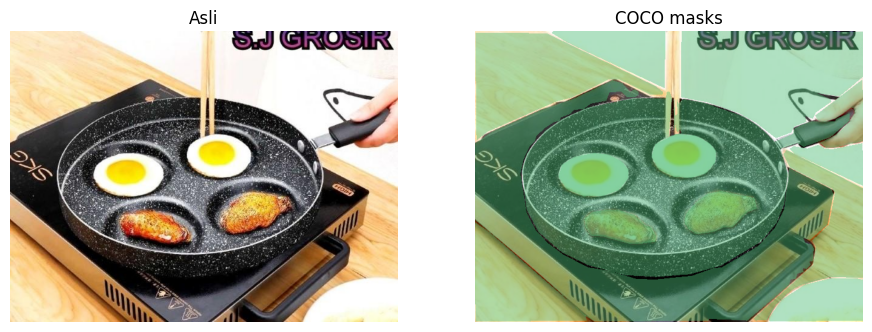

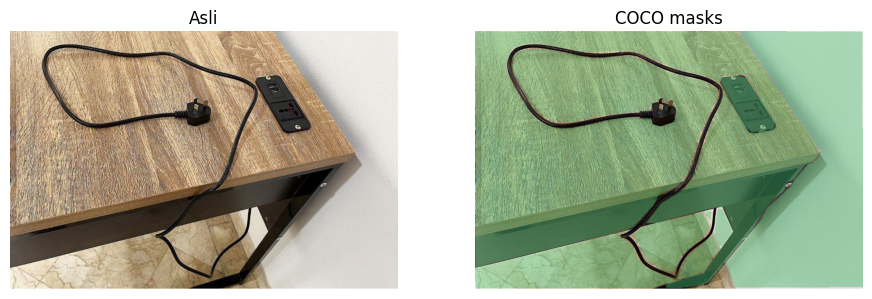

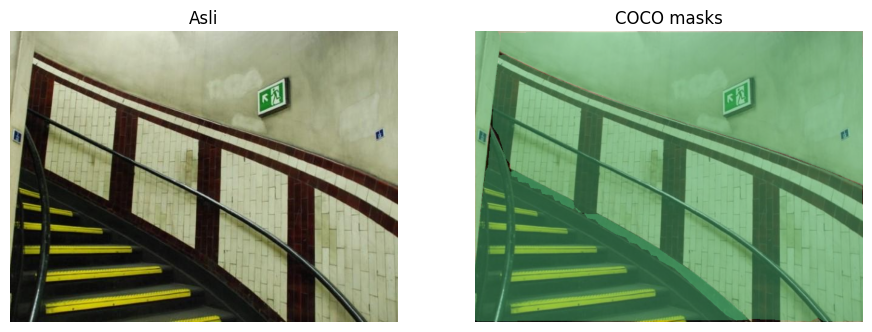

In [7]:
def image_path(split, image_record, root=DATA_ROOT):
    folder=Path(root)/split
    raw=Path(image_record['file_name'])
    options=[folder/raw, folder/raw.name, Path(root)/raw]
    return next((p for p in options if p.exists()), None)

def decode_mask(annotation, h, w):
    seg=annotation.get('segmentation')
    if not seg: return np.zeros((h,w), dtype=np.uint8)
    try:
        if isinstance(seg,list):
            rles=mask_utils.frPyObjects(seg,h,w)
            merged=mask_utils.merge(rles)
        elif isinstance(seg,dict) and isinstance(seg.get('counts'),list):
            merged=mask_utils.frPyObjects(seg,h,w)
        else:
            merged=seg
            if isinstance(merged,dict) and isinstance(merged.get('counts'),str):
                merged={**merged,'counts':merged['counts'].encode('ascii')}
        m=mask_utils.decode(merged)
        return (m.max(axis=2) if m.ndim==3 else m).astype(np.uint8)
    except Exception as exc:
        raise ValueError(f"Gagal decode mask annotation id={annotation.get('id')}: {exc}")

def preview_gt(split='train', number=3, seed=23):
    raw=json.loads(ANN[split].read_text()); rng=random.Random(seed)
    selected=rng.sample(raw['images'],min(number,len(raw['images'])))
    by_img={}
    for a in raw['annotations']: by_img.setdefault(a['image_id'],[]).append(a)
    for info in selected:
        path=image_path(split,info)
        if path is None: print('Missing image:',info['file_name']);continue
        rgb=np.array(Image.open(path).convert('RGB')); overlay=rgb.copy()
        for ann in by_img.get(info['id'],[]):
            m=decode_mask(ann,len(rgb),rgb.shape[1]).astype(bool)
            color=np.array([80,190,120],dtype=np.uint8)
            overlay[m]=(0.55*overlay[m]+0.45*color).astype(np.uint8)
        plt.figure(figsize=(11,4));plt.subplot(1,2,1);plt.imshow(rgb);plt.axis('off');plt.title('Asli')
        plt.subplot(1,2,2);plt.imshow(overlay);plt.axis('off');plt.title('COCO masks')
        plt.show()
preview_gt()

## 7. Pembentukan subset training 25%, 50%, dan 100%

Data training diacak dengan seed tetap, lalu dibentuk subset bersarang sehingga seluruh sampel 25% termasuk ke 50%, dan 50% termasuk ke 100%. Validation serta test set tidak masuk ke subset training.

In [8]:
ids=sorted(int(x['id']) for x in train_raw['images'])
rng=np.random.default_rng(SEED); shuffled=rng.permutation(ids).tolist()
SIZES={0.25:round(len(ids)*0.25),0.50:round(len(ids)*0.50),1.00:len(ids)}
SUBSETS={f: set(shuffled[:SIZES[f]]) for f in FRACTIONS}
if DRY_RUN:
    # mode pengecekan, agar conversion/training ringan; validation & test tidak diubah
    SUBSETS={f:set(shuffled[:min(8,len(v))]) for f,v in SUBSETS.items()}
assert SUBSETS[.25] <= SUBSETS[.5] <= SUBSETS[1.0]
for frac,subset in SUBSETS.items():
    (OUT/f'train_ids_{int(frac*100)}.json').write_text(json.dumps(sorted(subset),indent=2))
print('Jumlah gambar training per fraksi:',{f:len(s) for f,s in SUBSETS.items()})
print('DRY_RUN=True bukan jumlah final eksperimen; ubah False untuk 99/198/397.')

Jumlah gambar training per fraksi: {0.25: 99, 0.5: 198, 1.0: 397}
DRY_RUN=True bukan jumlah final eksperimen; ubah False untuk 99/198/397.


## 8. Konversi COCO menjadi format YOLO Segmentation

Mask instance pada dataset latih dikonversi menjadi polygon YOLO. Untuk anotasi dengan beberapa komponen polygon, kontur terbesar dipakai sebagai representasi YOLO dan selisihnya dicatat dalam laporan audit konversi. Data Mask R-CNN tetap menggunakan mask asli COCO.

In [9]:
YOLO_ROOT=OUT/'yolo_data'; YOLO_ROOT.mkdir(parents=True,exist_ok=True)
convert_log=[]

def coco_to_yolo_split(split, subset_ids=None):
    raw=json.loads(ANN[split].read_text())
    images=raw['images']; by_img={}
    for a in raw['annotations']:
        by_img.setdefault(int(a['image_id']),[]).append(a)
    folder=YOLO_ROOT/split
    (folder/'images').mkdir(parents=True,exist_ok=True)
    (folder/'labels').mkdir(parents=True,exist_ok=True)
    paths=[]
    for im in tqdm(images,desc=f'YOLO {split}'):
        if subset_ids is not None and int(im['id']) not in subset_ids: continue
        src=image_path(split,im)
        if src is None: raise FileNotFoundError(f'Image tidak ada: {im["file_name"]}')
        dest=folder/'images'/f"{int(im['id']):08d}{src.suffix.lower()}"
        if not dest.exists():
            try: os.symlink(src,dest)
            except OSError: shutil.copy2(src,dest)
        h,w=int(im['height']),int(im['width']); lines=[]
        for a in by_img.get(int(im['id']),[]):
            if int(a.get('iscrowd',0)): continue
            m=decode_mask(a,h,w)
            if not m.any():continue
            contours,_=cv2.findContours(m,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
            if not contours: continue
            areas=[cv2.contourArea(x) for x in contours]; largest=contours[int(np.argmax(areas))]
            retained=float(max(areas))/max(1.,float(sum(areas)))
            if retained < 0.9: convert_log.append({'split':split,'image_id':int(im['id']),'annotation_id':int(a['id']),'retained_area_fraction':round(retained,4)})
            poly=cv2.approxPolyDP(largest,epsilon=0.0005*cv2.arcLength(largest,True),closed=True).reshape(-1,2)
            if len(poly)<3:continue
            xy=np.column_stack([np.clip(poly[:,0]/w,0,1),np.clip(poly[:,1]/h,0,1)]).ravel()
            lines.append(str(YOLO_ID[int(a['category_id'])])+' '+' '.join(f'{v:.6f}' for v in xy))
        (folder/'labels'/f'{int(im["id"]):08d}.txt').write_text('\n'.join(lines))
        paths.append(str(dest.absolute()))
    return paths

all_train_paths=coco_to_yolo_split('train', SUBSETS[1.0])
val_paths=coco_to_yolo_split('valid')
test_paths=coco_to_yolo_split('test')
# YOLO image lists and corresponding subset labels; listing only subset images prevents data leakage
lookup={int(Path(p).stem):p for p in all_train_paths}
for frac,subset in SUBSETS.items():
    paths=[lookup[i] for i in sorted(subset)]
    (YOLO_ROOT/f'train_{int(frac*100)}.txt').write_text('\n'.join(paths)+'\n')
for split,paths in [('val',val_paths),('test',test_paths)]:
    (YOLO_ROOT/f'{split}.txt').write_text('\n'.join(paths)+'\n')
for frac in FRACTIONS:
    meta={'path':str(YOLO_ROOT.resolve()), 'train':str((YOLO_ROOT/f'train_{int(frac*100)}.txt').resolve()),'val':str((YOLO_ROOT/'val.txt').resolve()),'test':str((YOLO_ROOT/'test.txt').resolve()),'names':NAMES}
    (YOLO_ROOT/f'data_{int(frac*100)}.yaml').write_text(yaml.safe_dump(meta,sort_keys=False,allow_unicode=True))
pd.DataFrame(convert_log).to_csv(OUT/'coco_yolo_polygon_loss_audit.csv',index=False)
print('Mask multi-komponen dengan kemungkinan kehilangan:',len(convert_log));print('Contoh data:',YOLO_ROOT/'data_100.yaml')

YOLO train:   0%|          | 0/397 [00:00<?, ?it/s]

YOLO valid:   0%|          | 0/166 [00:00<?, ?it/s]

YOLO test:   0%|          | 0/359 [00:00<?, ?it/s]

Mask multi-komponen dengan kemungkinan kehilangan: 3
Contoh data: /kaggle/working/instance_seg_023/yolo_data/data_100.yaml


## 9. Pelatihan YOLO11n-seg dan YOLO11s-seg

Kedua model dilatih pada subset 25%, 50%, dan 100% menggunakan konfigurasi input, epoch, dan seed yang konsisten. Hasil latihan, grafik, log `results.csv`, serta checkpoint disimpan per eksperimen.

In [10]:
RUNS=OUT/'runs'; RUNS.mkdir(exist_ok=True)
train_records=[]

def yolo_train(model_name, frac):
    ckpt=RUNS/f'{model_name}_{int(frac*100)}'/'weights'/'best.pt'
    if ckpt.exists():
        print('Skip training; checkpoint ada:',ckpt); return str(ckpt)
    model=YOLO(MODEL_SPECS[model_name]['weights'])
    start=time.monotonic()
    def stop_on_limit(trainer):
        if (time.monotonic()-start)/60 >= MAX_MINUTES_PER_RUN:
            print('Batas waktu GPU tercapai; menghentikan training setelah epoch ini.')
            trainer.stop=True
    model.add_callback('on_train_epoch_end',stop_on_limit)
    model.train(data=str(YOLO_ROOT/f'data_{int(frac*100)}.yaml'),
                epochs=2 if DRY_RUN else YOLO_EPOCHS,
                imgsz=IMAGE_SIZE, batch=YOLO_BATCH, device=0,
                workers=NUM_WORKERS, project=str(RUNS),name=f'{model_name}_{int(frac*100)}',
                exist_ok=True,seed=SEED,deterministic=True,
                patience=100, pretrained=True,
                time=None,
                plots=True,save=True)
    elapsed=(time.monotonic()-start)/60
    train_records.append({'model':model_name,'fraction':frac,'minutes':round(elapsed,2),'gpu':torch.cuda.get_device_name(0),'checkpoint':str(ckpt)})
    with (OUT/'gpu_training_time.csv').open('a') as fh:
        pd.DataFrame(train_records[-1:]).to_csv(fh, index=False, header=(fh.tell()==0))
    return str(ckpt)

# Pengujian efek jumlah data diterapkan ke kedua model YOLO.
PLAN=[(name,f) for name in ('yolo11n','yolo11s') for f in (FRACTIONS if RUN_FULL_FACTORIAL else (1.0,))]
print('YOLO planned:',PLAN)
if RUN_TRAINING:
    for name, frac in PLAN:
        print('Training:',name,frac)
        yolo_train(name,frac)
else: print('Training dimatikan. Setelah audit, ubah DRY_RUN=False dan RUN_TRAINING=True.')

YOLO planned: [('yolo11n', 0.25), ('yolo11n', 0.5), ('yolo11n', 1.0), ('yolo11s', 0.25), ('yolo11s', 0.5), ('yolo11s', 1.0)]
Training: yolo11n 0.25
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/instance_seg_023/yolo_data/data_25.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/25      1.63G      1.386      3.709      4.483      1.473          0         44        512: 100% ━━━━━━━━━━━━ 13/13 7.3it/s 1.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 6.7it/s 1.6s
                   all        166       2021      0.159      0.133      0.105     0.0765      0.158      0.117      0.103     0.0623

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/25      1.75G      1.265       3.36      4.444      1.392          0         53        512: 100% ━━━━━━━━━━━━ 13/13 6.9it/s 1.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 6.4it/s 1.7s
                   all        166       2021      0.244       0.13      0.111     0.0813      0.247      0.114      0.109     0.0711

      Epoch   

## 10. Dataset loader dan arsitektur Mask R-CNN

COCO polygon dikonversi ke tensor gambar, bounding box, label, dan binary mask. Backbone ResNet-50 FPN pretrained dipakai untuk arsitektur two-stage, kemudian head klasifikasi dan mask diganti agar sesuai kelas dataset.

In [11]:
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF

class IndoorCocoDataset(Dataset):
    def __init__(self, split, ids=None, root=DATA_ROOT, annotation_path=None, image_folder=None, size=IMAGE_SIZE):
        self.split=split;self.root=Path(root);self.size=size
        self.annpath=Path(annotation_path) if annotation_path else ANN[split]
        self.raw=json.loads(self.annpath.read_text())
        self.items=[x for x in self.raw['images'] if ids is None or int(x['id']) in ids]
        self.by_img={}
        for a in self.raw['annotations']:
            if int(a.get('iscrowd',0))==0: self.by_img.setdefault(int(a['image_id']),[]).append(a)
        self.image_folder=Path(image_folder) if image_folder else None
    def __len__(self): return len(self.items)
    def __getitem__(self,idx):
        im=self.items[idx]
        if self.image_folder:
            candidate=self.image_folder/Path(im['file_name']).name
            path=candidate if candidate.exists() else self.image_folder/im['file_name']
        else: path=image_path(self.split,im,self.root)
        if path is None or not Path(path).exists(): raise FileNotFoundError(f'Gambar tidak ditemukan: {im["file_name"]}')
        rgb=np.asarray(Image.open(path).convert('RGB'))
        h,w=rgb.shape[:2]
        # Short-side resizing with capped max-size; original test dimensions restored by inference code later.
        scale=min(self.size/min(h,w),self.size*1.5/max(h,w))
        nh,nw=max(32,round(h*scale)),max(32,round(w*scale))
        rgb=cv2.resize(rgb,(nw,nh),interpolation=cv2.INTER_LINEAR)
        masks=[]; labels=[]; boxes=[]; areas=[]
        for a in self.by_img.get(int(im['id']),[]):
            old=int(a['category_id'])
            if old not in YOLO_ID: continue
            m=decode_mask(a,h,w)
            m=cv2.resize(m,(nw,nh),interpolation=cv2.INTER_NEAREST)
            ys,xs=np.where(m>0)
            if len(xs)==0:continue
            x1,y1,x2,y2=int(xs.min()),int(ys.min()),min(nw,int(xs.max())+1),min(nh,int(ys.max())+1)
            if x2<=x1 or y2<=y1:continue
            masks.append(m);labels.append(YOLO_ID[old]+1);boxes.append([x1,y1,x2,y2]);areas.append(float(m.sum()))
        target={'boxes':torch.as_tensor(boxes,dtype=torch.float32).reshape(-1,4),
                'labels':torch.as_tensor(labels,dtype=torch.int64),
                'masks':torch.as_tensor(np.stack(masks) if masks else np.zeros((0,nh,nw),np.uint8),dtype=torch.uint8),
                'image_id':torch.tensor(int(im['id'])),
                'area':torch.as_tensor(areas,dtype=torch.float32),
                'iscrowd':torch.zeros(len(labels),dtype=torch.int64)}
        return TF.to_tensor(Image.fromarray(rgb)),target

def collate_fn(batch):return tuple(zip(*batch))

from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

def create_maskrcnn(num_classes=NUM_CLASSES+1,pretrained=True):
    weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT if pretrained else None
    net=maskrcnn_resnet50_fpn(weights=weights,weights_backbone=None,
                             min_size=IMAGE_SIZE,max_size=int(IMAGE_SIZE*1.5),
                             box_detections_per_img=100)
    in_features=net.roi_heads.box_predictor.cls_score.in_features
    net.roi_heads.box_predictor=FastRCNNPredictor(in_features,num_classes)
    in_channels=net.roi_heads.mask_predictor.conv5_mask.in_channels
    hidden=256
    net.roi_heads.mask_predictor=MaskRCNNPredictor(in_channels,hidden,num_classes)
    return net

small_ds=IndoorCocoDataset('train',ids=set(list(SUBSETS[.25])[:2]))
if len(small_ds):
    img,t=small_ds[0];print('Sanity check tensor',img.shape,'masks',t['masks'].shape,'labels',t['labels'][:10])

Sanity check tensor torch.Size([3, 512, 683]) masks torch.Size([21, 512, 683]) labels tensor([55, 55, 45, 42, 21, 21, 21, 21, 12, 12])


## 11. Pelatihan Mask R-CNN pada tiga proporsi data

Model Mask R-CNN dilatih menggunakan subset yang sama. Training loss, checkpoint tiap epoch, status durasi, dan penggunaan GPU dicatat secara terpisah untuk 25%, 50%, dan 100%.

In [12]:
def mask_train(frac):
    name=f'maskrcnn_{int(frac*100)}'; folder=RUNS/name;folder.mkdir(exist_ok=True,parents=True)
    checkpoint=folder/'best.pt'
    if checkpoint.exists(): print('Checkpoint ditemukan:',checkpoint);return str(checkpoint)
    ds=IndoorCocoDataset('train',ids=SUBSETS[frac]);loader=DataLoader(ds,batch_size=MASK_BATCH,shuffle=True,
            num_workers=NUM_WORKERS,collate_fn=collate_fn)
    model=create_maskrcnn().to(DEVICE)
    optimizer=torch.optim.SGD(model.parameters(),lr=0.003,momentum=0.9,weight_decay=0.0005)
    scaler=torch.amp.GradScaler('cuda',enabled=(DEVICE=='cuda'))
    records=[];start=time.monotonic();epoch_max=2 if DRY_RUN else MASK_EPOCHS
    prev=folder/'last.pt'; start_epoch=0
    if prev.exists():
        prior=torch.load(prev,map_location='cpu',weights_only=False)
        model.load_state_dict(prior['model_state']); start_epoch=int(prior['epoch'])
        if (folder/'training_log.csv').exists(): records=pd.read_csv(folder/'training_log.csv').to_dict('records')
        print('Melanjutkan Mask R-CNN dari epoch:',start_epoch)
    for epoch in range(start_epoch,epoch_max):
        model.train();tot=0.;batches=0
        for images,targets in tqdm(loader,desc=f'{name} epoch {epoch+1}'):
            images=[x.to(DEVICE) for x in images];targets=[{k:v.to(DEVICE) for k,v in t.items()} for t in targets]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',enabled=(DEVICE=='cuda')):
                losses=model(images,targets);loss=sum(losses.values())
            if not torch.isfinite(loss):raise RuntimeError(f'Loss nonfinite: {loss}')
            scaler.scale(loss).backward();scaler.step(optimizer);scaler.update()
            tot+=float(loss.item());batches+=1
        elapsed=(time.monotonic()-start)/60
        row={'epoch':epoch+1,'train_loss':tot/max(batches,1),'elapsed_minutes':elapsed,'images':len(ds), 'fraction':frac}
        records.append(row);pd.DataFrame(records).to_csv(folder/'training_log.csv',index=False)
        # Last checkpoint persists for interrupted run; use final as best (validation AP not computed during training).
        torch.save({'model_state':model.state_dict(),'epoch':epoch+1,'num_classes':NUM_CLASSES+1,'fraction':frac},folder/'last.pt')
        print(row)
        if elapsed>=MAX_MINUTES_PER_RUN: print('Batas waktu training tercapai');break
    if (folder/'last.pt').exists(): shutil.copy2(folder/'last.pt',checkpoint)
    duration=(time.monotonic()-start)/60
    pd.DataFrame([{'model':'maskrcnn','fraction':frac,'minutes':duration,'checkpoint':str(checkpoint),'gpu':torch.cuda.get_device_name(0)}]).to_csv(folder/'gpu_usage.csv',index=False)
    del model;torch.cuda.empty_cache()
    return str(checkpoint)

MASK_PLAN=list(FRACTIONS) if RUN_FULL_FACTORIAL else [1.]
if RUN_TRAINING:
    for f in MASK_PLAN:mask_train(f)
else: print('Mask R-CNN training skipped.')

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 218MB/s]


maskrcnn_25 epoch 1:   0%|          | 0/50 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 2.9417656660079956, 'elapsed_minutes': 0.24388256748333106, 'images': 99, 'fraction': 0.25}


maskrcnn_25 epoch 2:   0%|          | 0/50 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 2.1255598294734956, 'elapsed_minutes': 0.6315266512333324, 'images': 99, 'fraction': 0.25}


... (52 outputs left out)

maskrcnn_100 epoch 9:   0%|          | 0/199 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.7622447659322364, 'elapsed_minutes': 8.406450490183333, 'images': 397, 'fraction': 1.0}


maskrcnn_100 epoch 10:   0%|          | 0/199 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 0.716880942783763, 'elapsed_minutes': 9.735345957399996, 'images': 397, 'fraction': 1.0}


## 12. Inferensi terstandar dan evaluasi COCO mask AP

Prediksi seluruh model dikonversi ke representasi COCO RLE yang seragam. Perhitungan AP, AP50, dan AP75 dilakukan menggunakan `pycocotools` pada test set yang sama agar dapat dibandingkan lintas keluarga model.

In [13]:
def get_checkpoint(model_name,frac=1.0):
    p=RUNS/f'{model_name}_{int(frac*100)}'/'weights'/'best.pt' if model_name.startswith('yolo') else RUNS/f'maskrcnn_{int(frac*100)}'/'best.pt'
    if not p.exists():raise FileNotFoundError(f'Belum ada checkpoint: {p}')
    return p

def predict_to_coco(model_name,checkpoint,annotation_json,image_folder,threshold=0.001):
    raw=json.loads(Path(annotation_json).read_text())
    images=raw['images'];output=[]
    if model_name.startswith('yolo'):
        model=YOLO(str(checkpoint))
    else:
        model=create_maskrcnn(pretrained=False).to(DEVICE)
        ckpt=torch.load(checkpoint,map_location='cpu',weights_only=False)
        model.load_state_dict(ckpt['model_state']);model.eval()
    for info in tqdm(images,desc=f'Predict {model_name}'):
        path=PERSONAL_IMG_PATHS[int(info['id'])] if image_folder is None and int(info['id']) in PERSONAL_IMG_PATHS else image_path('test',info) if image_folder is None else Path(image_folder)/Path(info['file_name']).name
        if image_folder is not None and not path.exists(): path=Path(image_folder)/info['file_name']
        if not path.exists():raise FileNotFoundError(path)
        rgb=np.asarray(Image.open(path).convert('RGB'))
        h,w=rgb.shape[:2]
        if model_name.startswith('yolo'):
            r=model.predict(source=str(path),imgsz=IMAGE_SIZE,conf=threshold,iou=.7,retina_masks=True,
                            max_det=100,verbose=False,device=0 if DEVICE=='cuda' else 'cpu')[0]
            if r.masks is None or r.boxes is None:continue
            pred_masks=r.masks.data.cpu().numpy()
            labels=r.boxes.cls.int().cpu().numpy()
            scores=r.boxes.conf.cpu().numpy()
            masks=[(cv2.resize(m,(w,h),interpolation=cv2.INTER_NEAREST) if m.shape!=(h,w) else m)>.5 for m in pred_masks]
            pairs=[(int(k),float(sc),mask) for k,sc,mask in zip(labels,scores,masks)]
        else:
            scale=min(IMAGE_SIZE/min(h,w),IMAGE_SIZE*1.5/max(h,w))
            nh,nw=max(32,round(h*scale)),max(32,round(w*scale))
            resized=cv2.resize(rgb,(nw,nh))
            x=TF.to_tensor(Image.fromarray(resized)).to(DEVICE)
            with torch.inference_mode():pred=model([x])[0]
            labels=pred['labels'].cpu().numpy();scores=pred['scores'].cpu().numpy()
            ms=pred['masks'].cpu().numpy()
            pairs=[]
            for lab,sc,m in zip(labels,scores,ms):
                if sc<threshold:continue
                mask=cv2.resize(m[0],(w,h),interpolation=cv2.INTER_LINEAR)>.5
                pairs.append((int(lab)-1,float(sc),mask))
        for cls,sc,mask in pairs:
            if cls not in COCO_ID or not mask.any():continue
            rle=mask_utils.encode(np.asfortranarray(mask.astype(np.uint8)))
            rle['counts']=rle['counts'].decode('ascii')
            output.append({'image_id':int(info['id']),'category_id':int(COCO_ID[cls]),'segmentation':rle,'score':float(sc)})
    del model
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return output

def evaluate_coco(gt_path,predictions,tag):
    gt=COCO(str(gt_path))
    if not predictions:
        print('Tidak ada prediksi:',tag)
        return {'mask_AP':0.0,'mask_AP50':0.0,'mask_AP75':0.0,'n_predictions':0}
    det=gt.loadRes(predictions)
    ev=COCOeval(gt,det,'segm')
    ev.params.imgIds=sorted(gt.getImgIds());ev.params.catIds=sorted(ACTIVE_IDS)
    ev.params.maxDets=[1,10,100]
    ev.evaluate();ev.accumulate();ev.summarize()
    return {'mask_AP':float(ev.stats[0]),'mask_AP50':float(ev.stats[1]),
            'mask_AP75':float(ev.stats[2]), 'n_predictions':len(predictions)}

EVALSETS={'original':{'json':ANN['test'],'images':DATA_ROOT/'test'}}
print('Original test:',EVALSETS['original'])

Original test: {'json': PosixPath('/kaggle/working/panoptic-indoor-segmentation-5/test/_annotations.coco.json'), 'images': PosixPath('/kaggle/working/panoptic-indoor-segmentation-5/test')}


## 13. Penyelarasan 40 foto asli dengan COCO hasil anotasi

ZIP/JSON anotasi dicari secara otomatis di Kaggle Input terpisah. Setiap `file_name` dicocokkan terhadap file gambar asli; pemeriksaan meliputi jumlah foto, dimensi piksel, ID kategori, format segmentation mask, duplikasi, dan gambar tanpa anotasi. **Evaluasi pribadi hanya dilakukan bila gambar dan anotasi yang dirujuk cocok**. File visualisasi overlay tidak dipakai sebagai gambar uji.

In [14]:
import zipfile, re

assert PERSONAL_PHOTO_DIR.exists(), f'Dataset 40 foto asli belum terpasang: {PERSONAL_PHOTO_DIR}'
assert PERSONAL_ANNOT_DIR.exists(), f'Dataset hasil anotasi belum terpasang: {PERSONAL_ANNOT_DIR}'

def list_photo_files(root):
    return sorted(p for p in Path(root).rglob('*') if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png','.webp','.bmp','.tif','.tiff'} and not any(x in p.parts for x in ('visualizations','masks')))

photos=list_photo_files(PERSONAL_PHOTO_DIR)
print('Jumlah file foto asli yang terdeteksi:',len(photos))
assert photos, 'Folder Kaggle Input foto asli kosong.'

zips=sorted(PERSONAL_ANNOT_DIR.rglob('*.zip'))
jsons=sorted(PERSONAL_ANNOT_DIR.rglob('*.json'))
if zips:
    chosen=max(zips,key=lambda p:p.stat().st_mtime)
    extract_dir=OUT/'personal_coco_extracted';extract_dir.mkdir(exist_ok=True)
    with zipfile.ZipFile(chosen) as zipf:
        for member in zipf.infolist():
            path=(extract_dir/member.filename).resolve()
            if not path.is_relative_to(extract_dir.resolve()):raise ValueError('ZIP mengandung path berbahaya')
        zipf.extractall(extract_dir)
    jsons=sorted(extract_dir.rglob('*.json'),key=lambda p:(p.name!='sota_annotations.coco.json',p.name!='_annotations.coco.json')) + jsons
    print('ZIP anotasi digunakan:',chosen)
assert jsons, 'COCO JSON belum ditemukan dalam folder/ZIP anotasi.'

personal_json=None;PERSONAL_RAW=None
for cand in jsons:
    try:
        data=json.loads(cand.read_text(encoding='utf-8'))
        if {'images','annotations','categories'} <= data.keys():
            if PERSONAL_RAW is None or len(data['images'])>len(PERSONAL_RAW['images']):
                PERSONAL_RAW=data;personal_json=cand
    except (OSError,ValueError,UnicodeError):pass
assert PERSONAL_RAW is not None, 'Tidak menemukan JSON format COCO lengkap.'
print('COCO anotasi:',personal_json,'| gambar:',len(PERSONAL_RAW['images']),'| anotasi:',len(PERSONAL_RAW['annotations']))

# Pencocokan dengan beberapa variasi penamaan hasil ekspor
by_exact={}
for p in photos: by_exact.setdefault(p.name.lower(),[]).append(p)
def stemkey(name):
    s = Path(name).stem.lower()

    # Hilangkan akhiran Roboflow
    s = re.sub(r'\.rf[._-][a-z0-9]+$', '', s)

    # Hilangkan akhiran visualisasi SOTA
    s = re.sub(r'_sota$', '', s)

    # Normalisasi karakter
    return re.sub(r'[^a-z0-9]', '', s)
by_stem={}
for p in photos: by_stem.setdefault(stemkey(p.name),[]).append(p)

PERSONAL_IMG_PATHS={};audits=[];missing=[]
for im in PERSONAL_RAW['images']:
    iid=int(im['id']); filename=Path(im['file_name']).name
    choices=by_exact.get(filename.lower(),[])
    if not choices: choices=by_stem.get(stemkey(filename),[])
    if len(choices)!=1:
        missing.append(filename);audits.append({'image_id':iid,'coco_file':filename,'match_count':len(choices),'status':'MISSING/AMBIGUOUS'});continue
    path=choices[0]
    with Image.open(path) as obj: realw,realh=obj.size
    ok=(realw==int(im['width']) and realh==int(im['height']))
    audits.append({'image_id':iid,'coco_file':filename,'match_count':1,'actual_file':path.name,'status':'OK' if ok else 'DIMENSION MISMATCH',
                   'expected_size':f"{im['width']}x{im['height']}",'actual_size':f'{realw}x{realh}'})
    if ok:PERSONAL_IMG_PATHS[iid]=path

audit_df=pd.DataFrame(audits);display(audit_df.head(20));audit_df.to_csv(OUT/'personal_filename_audit.csv',index=False)
assert not missing, 'Gagal mencocokkan nama file pada COCO dengan foto asli: '+str(missing[:8])+'; perbaiki pemetaan dulu.'
assert len(PERSONAL_IMG_PATHS)==len(PERSONAL_RAW['images']), 'Dimensi gambar tidak sesuai COCO. Perlu ekspor anotasi pada resolusi foto yang tepat.'
assert len(PERSONAL_RAW['images'])>=40, f'COCO hanya memuat {len(PERSONAL_RAW["images"])} gambar; wajib minimal 40. Perbarui ZIP anotasi.'

names_original={str(c['name']).strip():int(c['id']) for c in train_raw['categories']}
names_personal={int(c['id']):str(c['name']).strip() for c in PERSONAL_RAW['categories']}
unknown=sorted({names_personal.get(int(a['category_id']),'UNDEFINED') for a in PERSONAL_RAW['annotations'] if names_personal.get(int(a['category_id']),'UNDEFINED') not in names_original})
assert not unknown, f'Kelas tidak cocok dengan Panoptic v5: {unknown}'

mapped_anns=[]
for ann in PERSONAL_RAW['annotations']:
    item=dict(ann)
    item['category_id']=names_original[names_personal[int(item['category_id'])]]
    mapped_anns.append(item)
PERSONAL_RAW={**PERSONAL_RAW,'annotations':mapped_anns,'categories':train_raw['categories']}
image_ids={int(x['id']) for x in PERSONAL_RAW['images']}
annotated_ids={int(a['image_id']) for a in mapped_anns}
print('Gambar tanpa anotasi objek:',len(image_ids-annotated_ids),'(perlu audit: bisa benar-benar kosong atau belum teranotasi)')
for ann in mapped_anns:
    assert int(ann['image_id']) in image_ids
    assert ann.get('segmentation'),f'Anotasi {ann.get("id")} tidak memiliki mask.'
PERSONAL_JSON=OUT/'personal_test_mapped.coco.json'
PERSONAL_JSON.write_text(json.dumps(PERSONAL_RAW))
EVALSETS={'original':{'json':ANN['test'],'images':DATA_ROOT/'test'},'personal':{'json':PERSONAL_JSON,'images':None}}
print('DATASET PERSONAL SIAP: ',len(PERSONAL_RAW['images']),'gambar,',len(mapped_anns),'mask; file:',PERSONAL_JSON)

def locate_eval_image(info,split):
    return PERSONAL_IMG_PATHS[int(info['id'])] if split=='personal' else image_path('test',info)

Jumlah file foto asli yang terdeteksi: 40
COCO anotasi: /kaggle/input/datasets/berlianasarlita/personal-annotations/sota_annotations.coco.json | gambar: 40 | anotasi: 290


,image_id,coco_file,match_count,actual_file,status,expected_size,actual_size
0,1,IMG_20261125_144906_988.jpg,1,IMG_20261125_144906_988.jpg,OK,3072x3072,3072x3072
1,2,IMG_20261125_144923_055.jpg,1,IMG_20261125_144923_055.jpg,OK,3072x3072,3072x3072
2,3,IMG_20261125_144935_951.jpg,1,IMG_20261125_144935_951.jpg,OK,3072x3072,3072x3072
3,4,IMG_20261125_144953_942.jpg,1,IMG_20261125_144953_942.jpg,OK,3072x3072,3072x3072
4,5,IMG_20261125_144959_147.jpg,1,IMG_20261125_144959_147.jpg,OK,3072x3072,3072x3072
5,6,IMG_20261125_145159_718.jpg,1,IMG_20261125_145159_718.jpg,OK,3072x3072,3072x3072
6,7,IMG_20261125_145230_894.jpg,1,IMG_20261125_145230_894.jpg,OK,3072x3072,3072x3072
7,8,IMG_20261125_145237_007.jpg,1,IMG_20261125_145237_007.jpg,OK,3072x3072,3072x3072
8,9,IMG_20261125_145257_225.jpg,1,IMG_20261125_145257_225.jpg,OK,3072x3072,3072x3072
9,10,IMG_20261125_145315_698.jpg,1,IMG_20261125_145315_698.jpg,OK,3072x3072,3072x3072


Gambar tanpa anotasi objek: 0 (perlu audit: bisa benar-benar kosong atau belum teranotasi)
DATASET PERSONAL SIAP:  40 gambar, 290 mask; file: /kaggle/working/instance_seg_023/personal_test_mapped.coco.json


## 14. Evaluasi sembilan konfigurasi pada dua test set

Masing-masing checkpoint diuji pada test set asli dan pribadi. Prediksi disimpan sebagai COCO JSON, lalu dihitung mask AP@[.50:.95], AP50, dan AP75. Perbedaan metrik antara kedua test set menjadi dasar analisis domain shift.

In [15]:
eval_rows=[]
if RUN_EVALUATION:
    for name in ('yolo11n','yolo11s','maskrcnn'):
        for frac in FRACTIONS:
            checkpoint=get_checkpoint(name,frac)
            for split,info in EVALSETS.items():
                print('COCO EVAL:',name,frac,split)
                pred_path=OUT/f'predictions_{name}_{int(frac*100)}_{split}.json'
                if pred_path.exists():
                    predictions=json.loads(pred_path.read_text())
                else:
                    predictions=predict_to_coco(name,checkpoint,info['json'],info['images'],threshold=0.001)
                    pred_path.write_text(json.dumps(predictions))
                metrics=evaluate_coco(info['json'],predictions,f'{name}-{frac}-{split}')
                eval_rows.append({'model':name,'fraction':frac,'test_set':split,'n_images':len(json.loads(Path(info['json']).read_text())['images']),**metrics})
                pd.DataFrame(eval_rows).to_csv(OUT/'comparison_metrics.csv',index=False)
if eval_rows:
    metric_df=pd.DataFrame(eval_rows);display(metric_df)
    metric_df.to_csv(OUT/'comparison_metrics.csv',index=False)
else:print('Evaluasi tidak diaktifkan.')

COCO EVAL: yolo11n 0.25 original


Predict yolo11n:   0%|          | 0/359 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.73s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=4.22s).
Accumulating evaluation results...
DONE (t=0.99s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.068
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.105
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.068
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.029
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.053
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.099
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.087
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.128
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets

Predict yolo11n:   0%|          | 0/40 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.27s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.48s).
Accumulating evaluation results...
DONE (t=0.17s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.058
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.085
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.059
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.022
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.061
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.059
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.086
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

Predict yolo11n:   0%|          | 0/359 [00:00<?, ?it/s]

... (28 outputs left out)

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.52s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=3.51s).
Accumulating evaluation results...
DONE (t=0.83s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.061
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.112
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.061
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.017
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.059
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.090
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.086
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.150
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets

Predict maskrcnn:   0%|          | 0/40 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.11s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.35s).
Accumulating evaluation results...
DONE (t=0.15s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.102
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.149
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.109
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.042
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.107
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.143
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.194
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

,model,fraction,test_set,n_images,mask_AP,mask_AP50,mask_AP75,n_predictions
0,yolo11n,0.25,original,359,0.067947,0.104620,0.067816,35764
1,yolo11n,0.25,personal,40,0.058369,0.084955,0.058852,3873
2,yolo11n,0.50,original,359,0.056740,0.091030,0.056298,35761
3,yolo11n,0.50,personal,40,0.062704,0.085948,0.070496,3987
4,yolo11n,1.00,original,359,0.065894,0.106312,0.066957,35396
5,yolo11n,1.00,personal,40,0.086095,0.119899,0.098767,3893
6,yolo11s,0.25,original,359,0.077825,0.116248,0.081559,34547
7,yolo11s,0.25,personal,40,0.049862,0.078009,0.044063,3930
8,yolo11s,0.50,original,359,0.082890,0.128910,0.086194,34885
9,yolo11s,0.50,personal,40,0.048617,0.075463,0.045108,3984


## 15. Tabel perbandingan dan grafik domain shift

Mask AP setiap konfigurasi diplot sebagai fungsi jumlah data latih. Selisih antara nilai test set pribadi dan asli dihitung dalam satuan poin AP. Interpretasi dilakukan setelah memperhatikan perbedaan distribusi kelas dan kualitas ground truth.

test_set           original  personal  AP_gap_personal_minus_original
model    fraction                                                    
maskrcnn 0.25      0.027765  0.043874                        0.016109
         0.50      0.039860  0.056530                        0.016670
         1.00      0.061414  0.102376                        0.040963
yolo11n  0.25      0.067947  0.058369                       -0.009578
         0.50      0.056740  0.062704                        0.005965
         1.00      0.065894  0.086095                        0.020201
yolo11s  0.25      0.077825  0.049862                       -0.027963
         0.50      0.082890  0.048617                       -0.034273
         1.00      0.109565  0.102047                       -0.007518

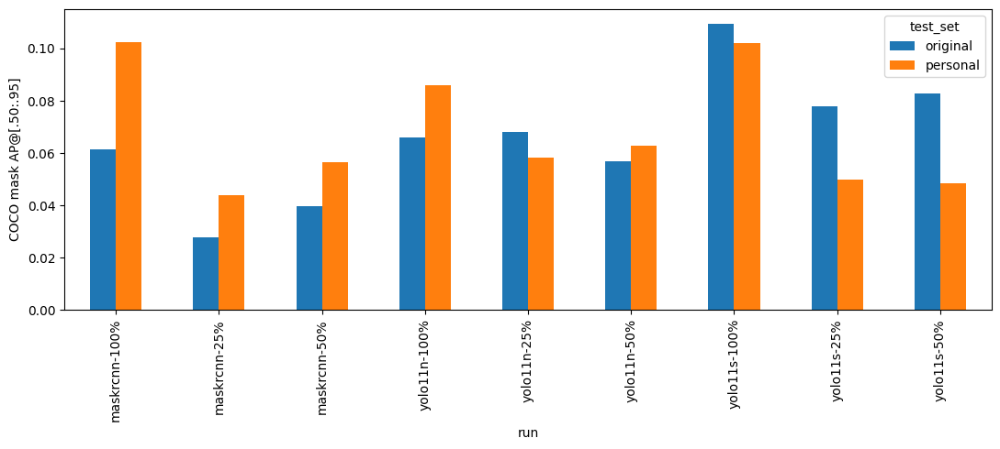

In [16]:
metrics_path=OUT/'comparison_metrics.csv'
if metrics_path.exists():
    m=pd.read_csv(metrics_path)
    pv=m.pivot_table(index=['model','fraction'],columns='test_set',values='mask_AP',aggfunc='first')
    if {'original','personal'}.issubset(pv.columns):
        pv['AP_gap_personal_minus_original']=pv['personal']-pv['original']
    display(pv)
    pv.to_csv(OUT/'domain_shift_summary.csv')
    ax=m.assign(run=m['model']+'-'+(m['fraction']*100).astype(int).astype(str)+'%').pivot(index='run',columns='test_set',values='mask_AP').plot(kind='bar',figsize=(11,5))
    ax.set_ylabel('COCO mask AP@[.50:.95]');plt.tight_layout();plt.savefig(OUT/'comparison_ap.png',dpi=160);plt.show()
else: print('Belum ada hasil metrik; jangan mengarang nilai untuk laporan.')

## 16. Grafik training loss dan audit log

Log setiap eksperimen dibaca langsung dari folder `runs` yang dibuat pada notebook yang sama. Grafik menampilkan riwayat loss per model serta menandai data yang tidak tersedia tanpa mengarang nilai. Log Mask R-CNN dan hasil Ultralytics YOLO disimpan bersama audit.

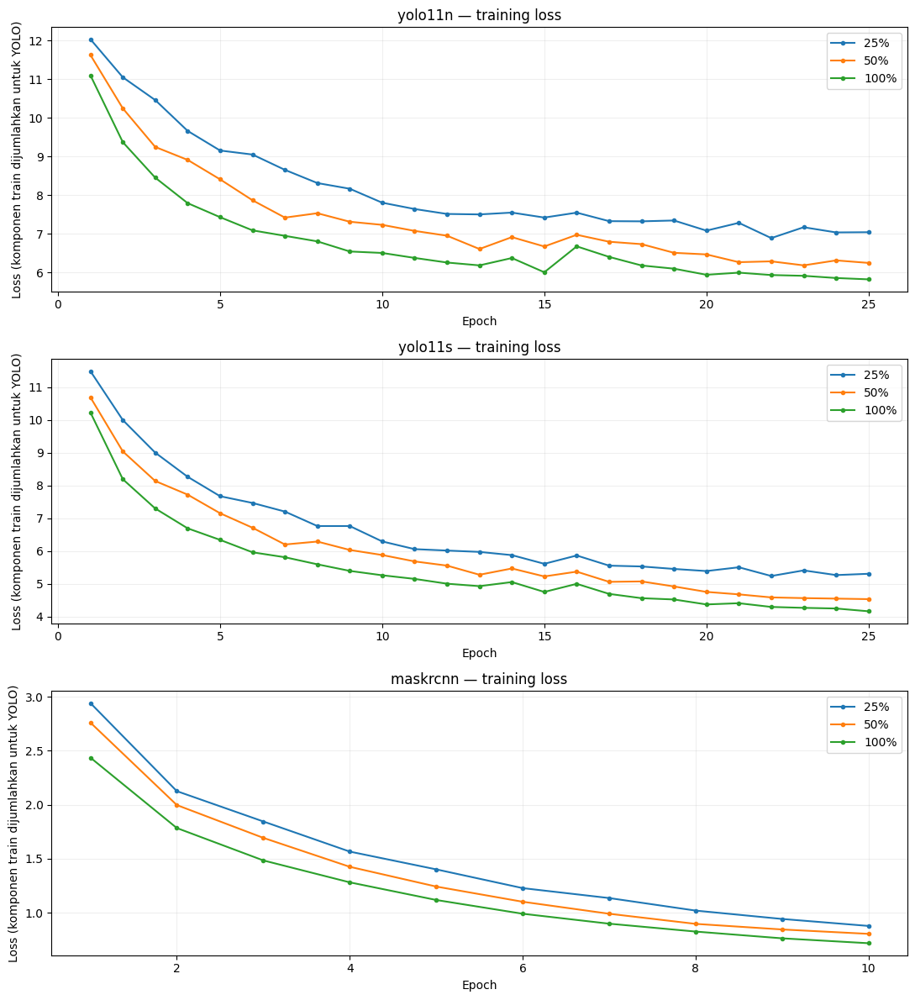

,model,pct,status,path
0,yolo11n,25,ok,/kaggle/working/instance_seg_023/runs/yolo11n_...
1,yolo11n,50,ok,/kaggle/working/instance_seg_023/runs/yolo11n_...
2,yolo11n,100,ok,/kaggle/working/instance_seg_023/runs/yolo11n_...
3,yolo11s,25,ok,/kaggle/working/instance_seg_023/runs/yolo11s_...
4,yolo11s,50,ok,/kaggle/working/instance_seg_023/runs/yolo11s_...
5,yolo11s,100,ok,/kaggle/working/instance_seg_023/runs/yolo11s_...
6,maskrcnn,25,ok,/kaggle/working/instance_seg_023/runs/maskrcnn...
7,maskrcnn,50,ok,/kaggle/working/instance_seg_023/runs/maskrcnn...
8,maskrcnn,100,ok,/kaggle/working/instance_seg_023/runs/maskrcnn...


In [17]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(3,1,figsize=(11,12),sharex=False)
log_status=[]
for ax,modelname in zip(axes,['yolo11n','yolo11s','maskrcnn']):
    found=0
    for frac in FRACTIONS:
        pct=int(frac*100); folder=RUNS/f'{modelname}_{pct}'
        log=folder/('training_log.csv' if modelname=='maskrcnn' else 'results.csv')
        if not log.exists():
            log_status.append({'model':modelname,'pct':pct,'status':'missing','path':str(log)}); continue
        d=pd.read_csv(log);d.columns=[x.strip() for x in d.columns]
        candidates=['train_loss'] if modelname=='maskrcnn' else ['train/box_loss','train/seg_loss','train/cls_loss','train/dfl_loss']
        present=[c for c in candidates if c in d.columns]
        if not present: log_status.append({'model':modelname,'pct':pct,'status':'columns_missing','path':str(log)});continue
        y=d[present].sum(axis=1); x=d['epoch'] if 'epoch' in d else range(1,len(d)+1)
        ax.plot(x,y,marker='.',label=f'{pct}%');found+=1
        log_status.append({'model':modelname,'pct':pct,'status':'ok','path':str(log)})
    ax.set_title(modelname+' — training loss')
    ax.set_xlabel('Epoch');ax.set_ylabel('Loss (komponen train dijumlahkan untuk YOLO)')
    if found:ax.legend();ax.grid(alpha=.2)
    else:ax.text(.5,.5,'Log training tidak ditemukan',ha='center',va='center',transform=ax.transAxes)
plt.tight_layout();plt.savefig(OUT/'training_loss_all.png',dpi=160);plt.show()
display(pd.DataFrame(log_status));pd.DataFrame(log_status).to_csv(OUT/'log_availability.csv',index=False)

## 17. Average Precision per kelas

Precision COCO pada sepuluh ambang IoU dirata-ratakan per kelas. Kelas tanpa ground truth diberi hasil kosong, bukan diasumsikan memiliki AP nol. Hasil per kelas mendukung analisis kelas sulit dan permintaan demo nilai AP salah satu kategori.

In [18]:
def per_class_ap(gt_json, pred_json):
    gt=COCO(str(gt_json))
    preds=json.loads(Path(pred_json).read_text())
    if not preds:
        return pd.DataFrame(columns=['category_id','class','mask_AP'])
    dt=gt.loadRes(preds)
    evaluator=COCOeval(gt,dt,'segm')
    evaluator.params.imgIds=sorted(gt.getImgIds())
    evaluator.params.catIds=sorted(ACTIVE_IDS)
    evaluator.params.maxDets=[1,10,100]
    evaluator.evaluate(); evaluator.accumulate()
    precision=evaluator.eval['precision']  # IoU × recall × category × area × max detections
    rows=[]
    for k,cid in enumerate(evaluator.params.catIds):
        p=precision[:,:,k,0,-1]
        valid=p[p>=0]
        rows.append({'category_id':cid,'class':CATEGORIES[cid],
                     'mask_AP':float(valid.mean()) if valid.size else float('nan')})
    return pd.DataFrame(rows).sort_values('mask_AP',ascending=False,na_position='last')

example_file=OUT/'predictions_yolo11n_100_original.json'
if example_file.exists():
    class_results=per_class_ap(ANN['test'],example_file)
    display(class_results.head(20))
    class_results.to_csv(OUT/'per_class_ap_yolo11n_100.csv',index=False)
else:
    print('AP per kelas menunggu hasil evaluasi yolo11n pada test asli.')

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.65s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=4.26s).
Accumulating evaluation results...
DONE (t=0.89s).


,category_id,class,mask_AP
55,56,teddy bear,0.437624
19,20,fire-extinguisher,0.349616
71,72,wallet,0.335457
42,43,potted plant,0.301723
38,39,person,0.281752
9,10,ceiling-merged,0.273153
1,2,bed,0.257482
11,12,chair,0.237904
23,24,food-other-merged,0.209321
20,21,floor-other-merged,0.176713


## 18. Perbandingan visual original–ground truth–tiga model

Setiap foto pribadi ditampilkan bersama mask anotasi dan prediksi checkpoint 100% dari ketiga model. Contoh visual disimpan dalam PNG untuk laporan serta pemeriksaan kegagalan instance segmentation.

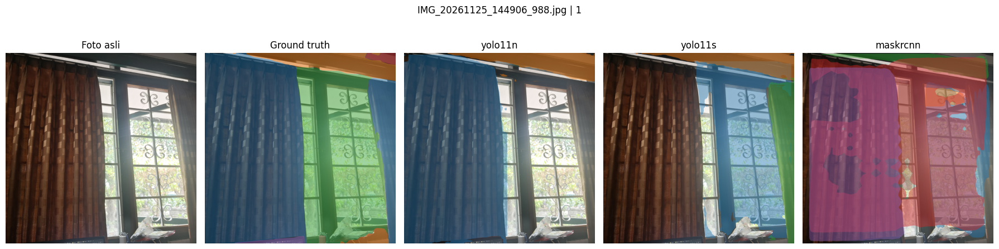

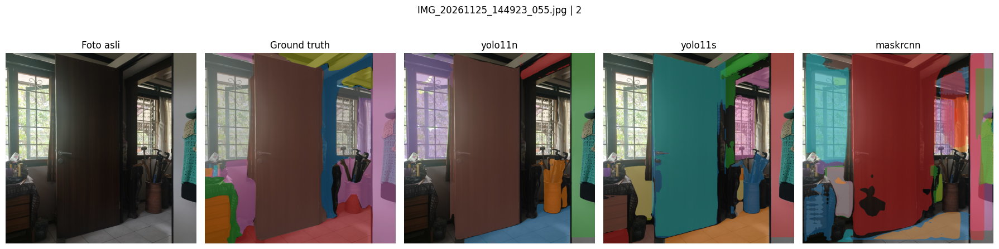

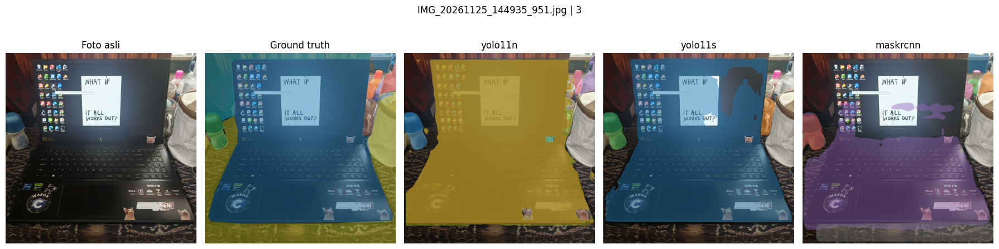

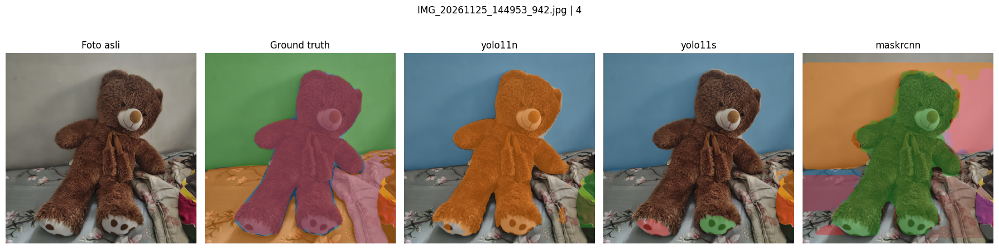

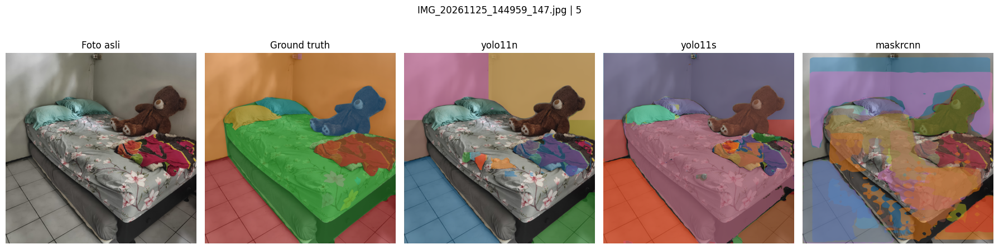

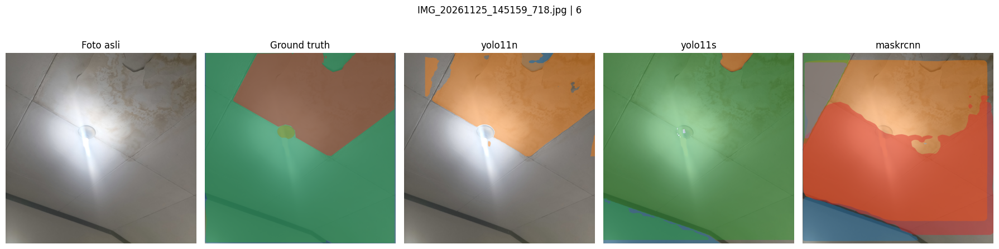

In [19]:
from PIL import Image

def overlay_rles(rgb, pred_items, h, w, show_label=True):
    canvas=rgb.astype(np.float32).copy()
    legend=[]
    for j,a in enumerate(pred_items):
        mask=decode_mask(a,h,w).astype(bool)
        if not mask.any(): continue
        color=np.array(plt.get_cmap('tab10')(j%10)[:3])*255
        canvas[mask]=.55*canvas[mask]+.45*color
        legend.append(CATEGORIES.get(int(a['category_id']),str(a['category_id'])))
    return np.uint8(np.clip(canvas,0,255)),legend

if PERSONAL_RAW is not None:
    by_img={}
    for a in PERSONAL_RAW['annotations']:by_img.setdefault(int(a['image_id']),[]).append(a)
    models=['yolo11n','yolo11s','maskrcnn']
    pred_cache={}
    for modelname in models:
        path=OUT/f'predictions_{modelname}_100_personal.json'
        pred_cache[modelname]=json.loads(path.read_text()) if path.exists() else []
    for info in PERSONAL_RAW['images'][:min(6,len(PERSONAL_RAW['images']))]:
        p=PERSONAL_IMG_PATHS[int(info['id'])];rgb=np.asarray(Image.open(p).convert('RGB'));h,w=rgb.shape[:2]
        fig,axes=plt.subplots(1,5,figsize=(18,5))
        axes[0].imshow(rgb);axes[0].set_title('Foto asli')
        o,_=overlay_rles(rgb,by_img.get(int(info['id']),[]),h,w)
        axes[1].imshow(o);axes[1].set_title('Ground truth')
        for ax,modelname in zip(axes[2:],models):
            selected=[a for a in pred_cache[modelname] if int(a['image_id'])==int(info['id']) and float(a['score'])>=DEMO_CONF]
            o,_=overlay_rles(rgb,selected,h,w);ax.imshow(o);ax.set_title(modelname)
        for ax in axes:ax.axis('off')
        fig.suptitle(p.name+' | '+str(info['id']));fig.tight_layout()
        f=OUT/f"visual_comparison_{int(info['id'])}.png";fig.savefig(f,dpi=160);plt.show()
else:print('Visualisasi lapangan menunggu foto beranotasi.')

## 19. Hasil AP untuk kelas terpilih

Nilai Average Precision kelas `chair` dan `trash-bin` ditampilkan bersama performa kelas lainnya. Hasil berasal dari evaluasi COCO, bukan hanya confidence prediksi pada satu gambar.

In [20]:
rows=[]
for split in EVALSETS:
    for name in ['yolo11n','yolo11s','maskrcnn']:
        p=OUT/f'predictions_{name}_100_{split}.json'
        if not p.exists():continue
        table=per_class_ap(EVALSETS[split]['json'],p)
        for target_name in ['chair','trash-bin']:
            match=table[table['class']==target_name]
            if len(match):rows.append({'test_set':split,'model':name,'class':target_name,'mask_AP':match.iloc[0]['mask_AP']})
if rows:
    class_df=pd.DataFrame(rows);display(class_df)
    class_df.to_csv(OUT/'ap_chair_trash_bin.csv',index=False)
else:print('Prediksi evaluasi kelas belum tersedia.')

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.64s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=4.30s).
Accumulating evaluation results...
DONE (t=0.88s).
loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.68s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=4.19s).
Accumulating evaluation results...
DONE (t=0.92s).
loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.54s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=3.59s).
Accumulating evaluation results...
DONE (t=0.84s).
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...

,test_set,model,class,mask_AP
0,original,yolo11n,chair,0.237904
1,original,yolo11n,trash-bin,0.006787
2,original,yolo11s,chair,0.278846
3,original,yolo11s,trash-bin,0.013385
4,original,maskrcnn,chair,0.136237
5,original,maskrcnn,trash-bin,0.032534
6,personal,yolo11n,chair,0.040368
7,personal,yolo11n,trash-bin,0.280297
8,personal,yolo11s,chair,0.021147
9,personal,yolo11s,trash-bin,0.262241


## 20. Eksperimen perubahan confidence threshold

Satu foto pribadi diuji pada confidence threshold berbeda untuk membandingkan perubahan jumlah deteksi dan mask. Analisis ini merupakan eksperimen inferensi terkontrol dan bukan pengganti eksperimen resolusi mask.

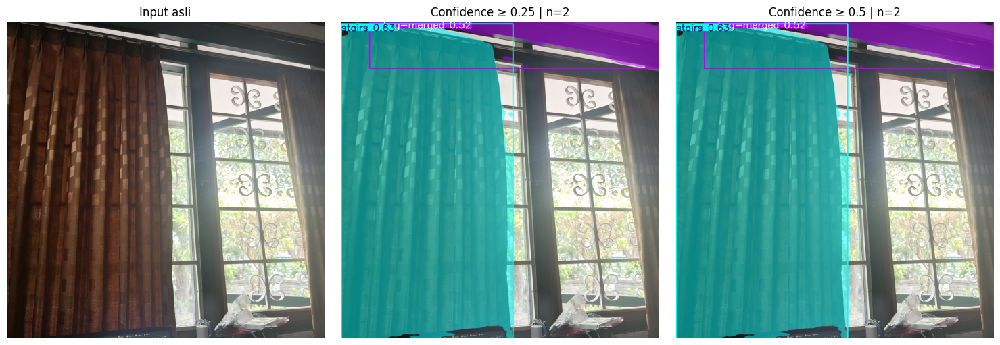

In [21]:
def threshold_demo(image_file=None,model_name='yolo11n',frac=1.0,thresholds=(0.25,0.50)):
    if image_file is None:
        if not PERSONAL_IMG_PATHS: print('Belum ada foto demo.');return
        image_file=next(iter(PERSONAL_IMG_PATHS.values()))
    image_file=Path(image_file)
    assert image_file.exists(),f'File tidak ada: {image_file}'
    assert model_name.startswith('yolo'),'Untuk demo threshold instan gunakan YOLO; evaluasi Mask R-CNN dilakukan pada cell sebelumnya.'
    model=YOLO(str(get_checkpoint(model_name,frac)))
    fig,axes=plt.subplots(1,len(thresholds)+1,figsize=(5*(len(thresholds)+1),5))
    axes[0].imshow(Image.open(image_file).convert('RGB'));axes[0].set_title('Input asli');axes[0].axis('off')
    for ax,thr in zip(axes[1:],thresholds):
        r=model.predict(str(image_file),conf=thr,imgsz=IMAGE_SIZE,retina_masks=True,verbose=False)[0]
        ax.imshow(r.plot()[:,:,::-1]);ax.set_title(f'Confidence ≥ {thr} | n={len(r.boxes)}');ax.axis('off')
    plt.tight_layout();plt.savefig(OUT/'demo_threshold.png',dpi=160);plt.show()

if PERSONAL_IMG_PATHS and (RUNS/'yolo11n_100'/'weights'/'best.pt').exists():
    threshold_demo()
else:print('Demo threshold akan berjalan jika checkpoint dan foto tersedia.')

## 21. Pemilihan lima kasus kegagalan berbasis bukti

Kelima foto dipilih berdasarkan kegagalan prediksi yang dapat diverifikasi dengan anotasi: objek terlewat, kelas salah, mask kurang tepat, atau instance tertukar. Pemilihan menggunakan prediksi dan ground truth, kemudian catatan mekanisme model dilengkapi berdasarkan inspeksi visual.

In [22]:
failure_template=OUT/'failure_cases.csv'
if not failure_template.exists():
    pd.DataFrame([{'image_id':'','file_name':'','model':'yolo11n','error_type':'missed_object / leak / wrong_class / merge / split',
                   'observed_evidence':'','mechanism_hypothesis':'','testable_prediction':'','result_after_experiment':'','conclusion':''} for _ in range(5)]).to_csv(failure_template,index=False)
print('Isi manual setelah inspeksi foto:',failure_template)

def show_failure_image(image_filename,model_name='yolo11n',frac=1.0,conf=.25,imgsz=IMAGE_SIZE):
    assert 'personal' in EVALSETS,'Isi PERSONAL_JSON terlebih dahulu.'
    path=next((p for p in PERSONAL_IMG_PATHS.values() if p.name==image_filename),None)
    if path is None or not path.exists():raise FileNotFoundError(image_filename)
    assert model_name.startswith('yolo'),'Visualisasi helper ini untuk YOLO; analisis Mask R-CNN pakai prediksi COCO JSON di bawah.'
    model=YOLO(str(get_checkpoint(model_name,frac)))
    result=model.predict(str(path),imgsz=imgsz,conf=conf,retina_masks=True,verbose=False)[0]
    plt.figure(figsize=(10,6));plt.imshow(result.plot()[:,:,::-1]);plt.axis('off');plt.title(f'{model_name}, imgsz={imgsz}');plt.show()

# Contoh pemakaian (setelah 40 foto siap):
# show_failure_image('nama_file.jpg',model_name='yolo11n')

Isi manual setelah inspeksi foto: /kaggle/working/instance_seg_023/failure_cases.csv


## 22. Eksperimen kecil untuk memeriksa dugaan mekanisme kegagalan

Lima gambar terpilih diuji ulang dengan dua resolusi input YOLO, dengan checkpoint dan confidence tetap. Perbedaan mask AP dan jumlah prediksi dipakai untuk menguji dugaan bahwa resolusi input memengaruhi bentuk mask. Hasil tidak boleh langsung dianggap sebagai bukti kausal tanpa membaca perubahan kualitas mask.

In [23]:
def slice_coco_images(json_path,selected_ids,out_file):
    raw=json.loads(Path(json_path).read_text());ids=set(map(int,selected_ids))
    small={**raw,'images':[x for x in raw['images'] if int(x['id']) in ids],
           'annotations':[x for x in raw['annotations'] if int(x['image_id']) in ids]}
    Path(out_file).write_text(json.dumps(small));return Path(out_file)

def resolution_failure_test(image_ids,model_name='yolo11n',frac=1.0):
    assert 'personal' in EVALSETS,'Belum ada test pribadi.'
    ids=list(map(int,image_ids));assert len(set(ids))==5,'Pilih tepat lima image_id unik yang benar-benar gagal.'
    src=EVALSETS['personal'];gt_small=slice_coco_images(src['json'],ids,OUT/'five_failures_gt.json')
    model=YOLO(str(get_checkpoint(model_name,frac)));raw=json.loads(gt_small.read_text())
    rows=[]
    for sz in [320,960]:
        predictions=[]
        for info in raw['images']:
            path=PERSONAL_IMG_PATHS[int(info['id'])]
            rgb=np.array(Image.open(path).convert('RGB'));h,w=rgb.shape[:2]
            r=model.predict(str(path),imgsz=sz,conf=.001,max_det=100,retina_masks=True,verbose=False)[0]
            if r.masks is None:continue
            for cls,score,m in zip(r.boxes.cls.int().cpu().tolist(),r.boxes.conf.cpu().tolist(),r.masks.data.cpu().numpy()):
                if cls not in COCO_ID:continue
                if m.shape!=(h,w):m=cv2.resize(m,(w,h),interpolation=cv2.INTER_NEAREST)
                mask=(m>.5).astype(np.uint8)
                if not mask.any():continue
                rle=mask_utils.encode(np.asfortranarray(mask));rle['counts']=rle['counts'].decode('ascii')
                predictions.append({'image_id':int(info['id']),'category_id':COCO_ID[cls],'score':score,'segmentation':rle})
        (OUT/f'failure_resolution_{sz}.json').write_text(json.dumps(predictions))
        metrics=evaluate_coco(gt_small,predictions,f'failure-imgsz-{sz}')
        rows.append({'imgsz':sz,**metrics})
    table=pd.DataFrame(rows);table.to_csv(OUT/'failure_resolution_experiment.csv',index=False)
    return table

# Eksperimen dijalankan setelah pemilihan lima kasus berdasarkan audit pada bagian berikutnya.

## 23. Bukti proses, EXIF foto, dan deklarasi penggunaan AI

Cell berikut mencatat metadata EXIF asli, hash file, waktu GPU, template logbook, dan deklarasi AI. Berkas hipotesis yang wajib ditulis sebelum training serta commit Git diperiksa terpisah; keduanya tidak dihasilkan mundur seolah-olah sudah ada.

In [24]:
logbook=OUT/'logbook.csv'
if not logbook.exists():
    pd.DataFrame(columns=['date','activity','model','data_fraction','start_time','end_time','gpu_minutes','obstacle','decision','evidence_path']).to_csv(logbook,index=False)
ai_log=OUT/'ai_usage_log.csv'
if not ai_log.exists():
    pd.DataFrame(columns=['date','tool','main_prompt','AI_suggestion','verification','mistake_or_limitation','fix','evidence']).to_csv(ai_log,index=False)
print('Logbook:',logbook,'\nAI disclosure:',ai_log)

# EXIF data original smartphone photos, if uploaded separately as local input:
ORIGINAL_PHOTO_DIR = PERSONAL_PHOTO_DIR
if ORIGINAL_PHOTO_DIR is not None:
    from PIL.ExifTags import TAGS
    exif_records=[]
    for p in Path(ORIGINAL_PHOTO_DIR).rglob('*'):
        if p.suffix.lower() not in ['.jpg','.jpeg','.tif','.tiff']:continue
        with Image.open(p) as im:
            exif=im.getexif()
            vals={str(TAGS.get(k,k)):str(v) for k,v in exif.items()}
            exif_records.append({'file':p.name,'sha256':hashlib.sha256(p.read_bytes()).hexdigest(),**vals})
    pd.DataFrame(exif_records).to_csv(OUT/'original_photo_exif.csv',index=False)
    print('EXIF:',len(exif_records),'files')
else: print('EXIF asli belum tersedia.')

Logbook: /kaggle/working/instance_seg_023/logbook.csv 
AI disclosure: /kaggle/working/instance_seg_023/ai_usage_log.csv
EXIF: 40 files


### Verifikasi EXIF, kondisi sulit, dan bukti anotasi

EXIF diperiksa untuk menunjukkan metadata yang masih tertanam dalam foto asli. Label kondisi sulit (`low_light`, `backlight`, `occlusion`, `extreme_angle`) merupakan observasi lapangan yang harus dicatat berdasarkan foto; label tersebut tidak dihasilkan otomatis tanpa verifikasi. Screenshot proses anotasi perlu disimpan bersama bukti sumbernya.

In [25]:
# Data kondisi sulit diisi berdasarkan pemeriksaan 40 foto, bukan prediksi otomatis.
condition_path=OUT/'photo_condition_review.csv'
if not condition_path.exists():
    pd.DataFrame([{'file':p.name,'low_light':'','backlight':'','occlusion':'','extreme_angle':'','reviewed_by':'','evidence_path':''} for p in photos]).to_csv(condition_path,index=False)
conditions=pd.read_csv(condition_path)
verified=conditions[['low_light','backlight','occlusion','extreme_angle']].astype(str).apply(lambda s:s.str.strip().str.lower().isin(['yes','true','1','ya']))
reviewed=conditions['reviewed_by'].fillna('').astype(str).str.strip().ne('')
print('Foto total:',len(photos),'| Peninjauan kondisi sulit didokumentasikan:',int(reviewed.sum()),'| Foto sulit terverifikasi:',int((verified.any(axis=1)&reviewed).sum()))
print('Template review:',condition_path)
print('Bukti screenshot anotasi harus dilampirkan dari Roboflow; notebook tidak menghasilkan screenshot palsu.')

Foto total: 40 | Peninjauan kondisi sulit didokumentasikan: 0 | Foto sulit terverifikasi: 0
Template review: /kaggle/working/instance_seg_023/photo_condition_review.csv
Bukti screenshot anotasi harus dilampirkan dari Roboflow; notebook tidak menghasilkan screenshot palsu.


### Identifikasi kandidat lima kegagalan secara objektif

Prediksi model YOLO11n-seg 100% dicocokkan dengan mask ground truth menggunakan greedy matching berdasarkan kelas dan IoU 0,50. Foto dengan false negative, false positive, atau kualitas mask buruk diprioritaskan sebagai kandidat. Pemilihan final dan penjelasan penyebab tetap diverifikasi melalui gambar.

In [26]:
from pycocotools import mask as _cocomask

def gt_mask_from_ann(a, im):
    return decode_mask(a,int(im['height']),int(im['width'])).astype(bool)

def matching_audit_for_image(im,gt_anns,pred_anns,iou_thr=0.5):
    h,w=int(im['height']),int(im['width'])
    # Skala audit disamakan untuk menghemat RAM; AP resmi tetap dihitung pada resolusi asli.
    aw,ah=768,max(1,round(h*768/w))
    gt=[(int(a['category_id']),cv2.resize(gt_mask_from_ann(a,im).astype(np.uint8),(aw,ah),interpolation=cv2.INTER_NEAREST).astype(bool)) for a in gt_anns if not int(a.get('iscrowd',0))]
    pred=[(int(a['category_id']),cv2.resize(_cocomask.decode({**a['segmentation'],'counts':a['segmentation']['counts'].encode() if isinstance(a['segmentation'].get('counts'),str) else a['segmentation']['counts']}).astype(np.uint8),(aw,ah),interpolation=cv2.INTER_NEAREST).astype(bool),float(a.get('score',0))) for a in pred_anns if float(a.get('score',0))>=0.25]
    pairs=[]
    for gi,(gc,gm) in enumerate(gt):
        for pi,(pc,pm,score) in enumerate(pred):
            if gc!=pc:continue
            inter=np.logical_and(gm,pm).sum(); union=np.logical_or(gm,pm).sum()
            iou=float(inter/union) if union else 0.
            pairs.append((iou,gi,pi))
    matches=[];matched_gt=set();matched_pred=set()
    for iou,gi,pi in sorted(pairs,reverse=True):
        if iou<iou_thr:break
        if gi in matched_gt or pi in matched_pred:continue
        matched_gt.add(gi);matched_pred.add(pi);matches.append(iou)
    return {'gt_count':len(gt),'pred_count':len(pred),'TP':len(matches),'FN':len(gt)-len(matches),
            'FP':len(pred)-len(matches),'mean_matched_iou':np.mean(matches) if matches else 0.,
            'error_score':len(gt)-len(matches)+len(pred)-len(matches)+(1-np.mean(matches) if matches else 1.)}

if RUN_EVALUATION:
    gt_by_image={}
    for a in PERSONAL_RAW['annotations']:gt_by_image.setdefault(int(a['image_id']),[]).append(a)
    pred_json=OUT/'predictions_yolo11n_100_personal.json'
    preds=json.loads(pred_json.read_text()); pred_by_img={}
    for a in preds:pred_by_img.setdefault(int(a['image_id']),[]).append(a)
    reviews=[]
    for im in PERSONAL_RAW['images']:
        iid=int(im['id']);stat=matching_audit_for_image(im,gt_by_image.get(iid,[]),pred_by_img.get(iid,[]))
        reviews.append({'image_id':iid,'file_name':im['file_name'],**stat})
    failure_audit=pd.DataFrame(reviews).sort_values('error_score',ascending=False)
    failure_audit.to_csv(OUT/'failure_candidate_ranking.csv',index=False)
    display(failure_audit.head(10))
    FIVE_FAILED_IMAGE_IDS=failure_audit.head(5)['image_id'].astype(int).tolist()
    print('Lima kandidat ID:',FIVE_FAILED_IMAGE_IDS)
else:FIVE_FAILED_IMAGE_IDS=[]

,image_id,file_name,gt_count,pred_count,TP,FN,FP,mean_matched_iou,error_score
32,33,IMG_20261125_145900_042.jpg,11,12,0,11,12,0.000000,24.000000
4,5,IMG_20261125_144959_147.jpg,14,13,2,12,11,0.852413,23.147587
30,31,IMG_20261125_145837_298.jpg,11,9,0,11,9,0.000000,21.000000
38,39,chair.jpg,16,9,3,13,6,0.789875,19.210125
36,37,IMG_20261125_150241_555.jpg,15,6,2,13,4,0.806106,17.193894
2,3,IMG_20261125_144935_951.jpg,12,11,3,9,8,0.866517,17.133483
1,2,IMG_20261125_144923_055.jpg,12,6,1,11,5,0.772116,16.227884
7,8,IMG_20261125_145237_007.jpg,13,7,2,11,5,0.864341,16.135659
31,32,IMG_20261125_145849_183.jpg,9,6,0,9,6,0.000000,16.000000
18,19,IMG_20261125_145443_575.jpg,9,4,0,9,4,0.000000,14.000000


Lima kandidat ID: [33, 5, 31, 39, 37]


### Lima visualisasi kasus kegagalan

Untuk setiap kandidat, gambar asli dibandingkan dengan ground truth dan prediksi YOLO11n-seg. Nilai TP, FN, FP, dan mean IoU digunakan sebagai bukti kuantitatif awal. Hasil ini perlu ditinjau untuk menentukan lima kegagalan yang akan dianalisis mekanismenya.

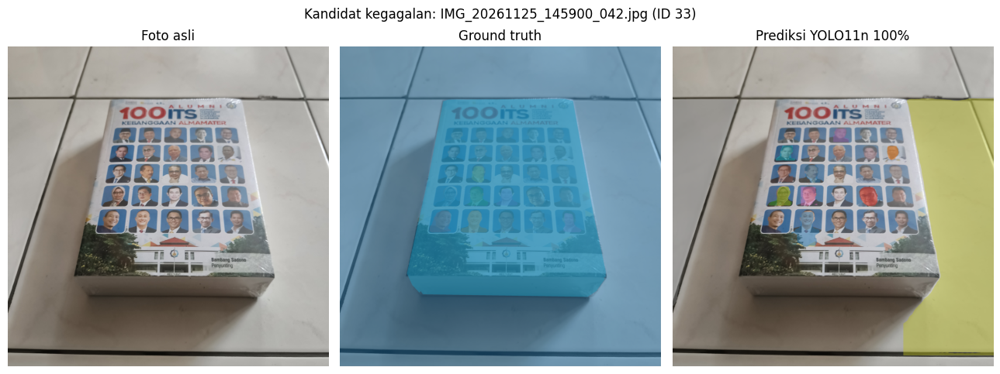

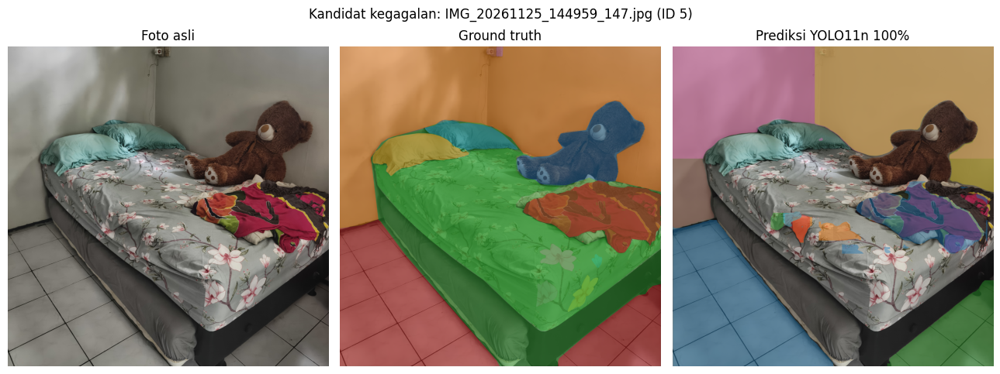

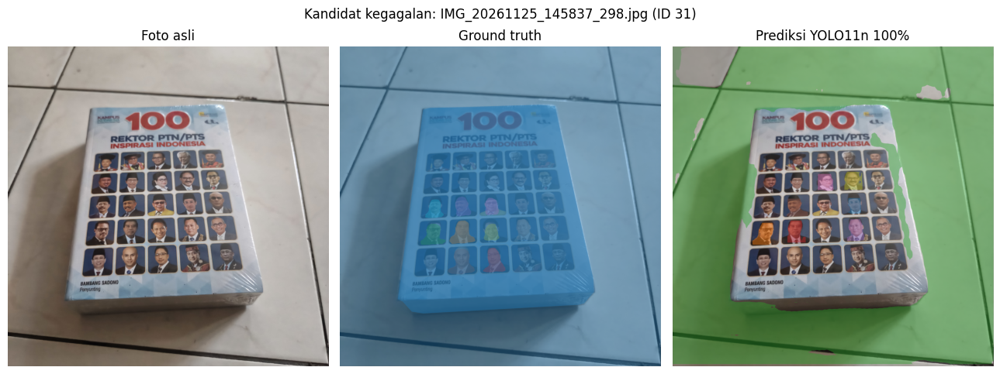

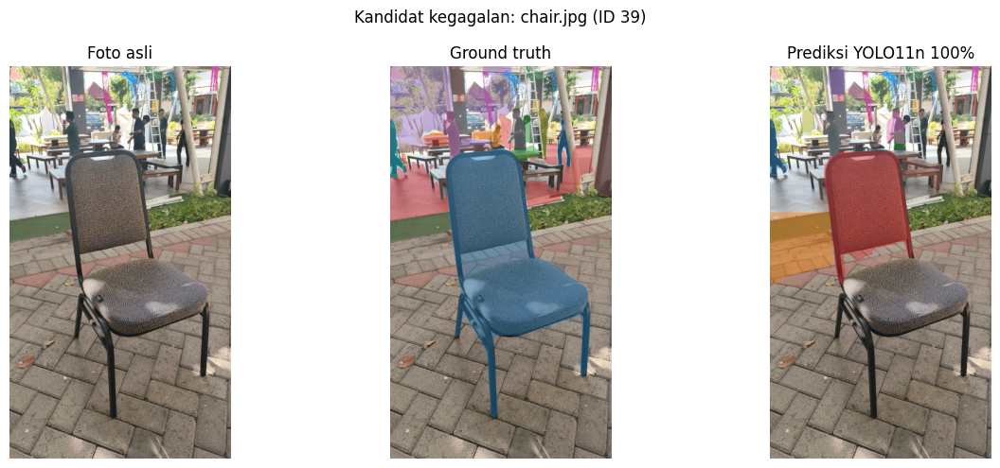

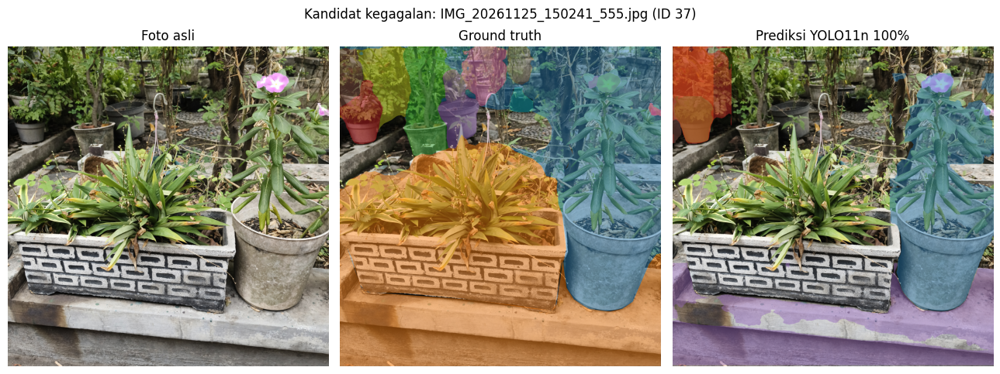

In [27]:
if FIVE_FAILED_IMAGE_IDS:
    pred_map={}
    for a in preds: pred_map.setdefault(int(a['image_id']),[]).append(a)
    for iid in FIVE_FAILED_IMAGE_IDS:
        im=next(x for x in PERSONAL_RAW['images'] if int(x['id'])==iid)
        rgb=np.asarray(Image.open(PERSONAL_IMG_PATHS[iid]).convert('RGB'));h,w=rgb.shape[:2]
        gt_overlay,_=overlay_rles(rgb,gt_by_image.get(iid,[]),h,w)
        pred_overlay,_=overlay_rles(rgb,[x for x in pred_map.get(iid,[]) if x.get('score',0)>=0.25],h,w)
        fig,axs=plt.subplots(1,3,figsize=(13,5))
        for ax,arr,title in zip(axs,[rgb,gt_overlay,pred_overlay],['Foto asli','Ground truth','Prediksi YOLO11n 100%']):
            ax.imshow(arr);ax.axis('off');ax.set_title(title)
        fig.suptitle(f'Kandidat kegagalan: {im["file_name"]} (ID {iid})')
        fig.tight_layout();fig.savefig(OUT/f'failure_case_{iid}.png',dpi=140,bbox_inches='tight');plt.show()
else: print('Tidak ada kandidat kegagalan yang tersedia.')

### Eksperimen pembuktian pada lima kegagalan

Perbedaan input `imgsz=320` dan `imgsz=960` diuji pada lima foto kandidat. Kontrol model dan checkpoint dijaga konstan; metrik AP dihitung untuk subset tersebut. Hasil dipakai untuk menerima atau menolak dugaan sementara mengenai pengaruh resolusi terhadap mask.

In [28]:
if RUN_FAILURE_EXPERIMENT and RUN_EVALUATION and len(FIVE_FAILED_IMAGE_IDS)==5:
    display(resolution_failure_test(FIVE_FAILED_IMAGE_IDS,model_name='yolo11n',frac=1.0))
else:
    print('Eksperimen lima kegagalan dilewati; cek RUN_FAILURE_EXPERIMENT dan ketersediaan kandidat.')

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.03s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.06s).
Accumulating evaluation results...
DONE (t=0.04s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.032
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.071
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.013
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.011
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.036
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.016
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.047
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

,imgsz,mask_AP,mask_AP50,mask_AP75,n_predictions
0,320,0.032009,0.070846,0.012898,420
1,960,0.110929,0.234923,0.090726,500


### Penjelasan kasus kegagalan dan pemenuhan dokumentasi

Hasil pemeringkatan lima foto dan eksperimen resolusi disimpan otomatis. Analisis mekanisme yang menautkan pengamatan ke arsitektur harus ditulis setelah visualisasi diperiksa; catatan dibuat pada file `failure_case_analysis.csv`. Bukti commit Git dan hipotesis bertanggal tetap memerlukan berkas asli yang dibuat pada waktu sebenarnya.

In [29]:
five_report=OUT/'failure_case_analysis.csv'
if not five_report.exists():
    pd.DataFrame([{'image_id':i,'file_name':next((r['file_name'] for r in reviews if r['image_id']==i),''),
                   'observed_failure':'','visual_evidence':'','mechanism_explanation':'',
                   'experiment_result':'','interpretation':'','reviewer':''} for i in FIVE_FAILED_IMAGE_IDS]).to_csv(five_report,index=False)
print('Formulir 5 kasus:',five_report)
print('Lampirkan screenshot/prompt AI, bukti koreksi kesalahan AI, logbook waktu GPU, dan riwayat commit Git.')

Formulir 5 kasus: /kaggle/working/instance_seg_023/failure_case_analysis.csv
Lampirkan screenshot/prompt AI, bukti koreksi kesalahan AI, logbook waktu GPU, dan riwayat commit Git.


## 24. Audit persyaratan tugas dan kelengkapan output

Checkpoint sembilan konfigurasi, evaluasi dua test set, visualisasi, log training, riwayat GPU, lima kasus kegagalan, dan berkas bukti administrasi diperiksa. Hasil yang belum tersedia ditandai secara eksplisit agar laporan tidak mengklaim pekerjaan yang belum terdokumentasi.

In [30]:
audit_rows=[]
for name in ('yolo11n','yolo11s','maskrcnn'):
    for f in FRACTIONS:
        p=RUNS/f'{name}_{int(f*100)}'/('weights/best.pt' if name.startswith('yolo') else 'best.pt')
        audit_rows.append({'model':name,'data_fraction':f,'checkpoint_exists':p.exists(), 'checkpoint_path':str(p)})
display(pd.DataFrame(audit_rows))
if (OUT/'comparison_metrics.csv').exists():
    metrics=pd.read_csv(OUT/'comparison_metrics.csv')
    display(metrics[['model','fraction','test_set','mask_AP','mask_AP50','mask_AP75']])
else:
    print('Belum ada comparison_metrics.csv.')
print('Test pribadi tersedia:', 'personal' in EVALSETS)
print('Bukti hipotesis awal, riwayat Git, log anotasi, dan 5 kegagalan harus diperiksa terpisah.')

,model,data_fraction,checkpoint_exists,checkpoint_path
0,yolo11n,0.25,True,/kaggle/working/instance_seg_023/runs/yolo11n_...
1,yolo11n,0.50,True,/kaggle/working/instance_seg_023/runs/yolo11n_...
2,yolo11n,1.00,True,/kaggle/working/instance_seg_023/runs/yolo11n_...
3,yolo11s,0.25,True,/kaggle/working/instance_seg_023/runs/yolo11s_...
4,yolo11s,0.50,True,/kaggle/working/instance_seg_023/runs/yolo11s_...
5,yolo11s,1.00,True,/kaggle/working/instance_seg_023/runs/yolo11s_...
6,maskrcnn,0.25,True,/kaggle/working/instance_seg_023/runs/maskrcnn...
7,maskrcnn,0.50,True,/kaggle/working/instance_seg_023/runs/maskrcnn...
8,maskrcnn,1.00,True,/kaggle/working/instance_seg_023/runs/maskrcnn...


,model,fraction,test_set,mask_AP,mask_AP50,mask_AP75
0,yolo11n,0.25,original,0.067947,0.104620,0.067816
1,yolo11n,0.25,personal,0.058369,0.084955,0.058852
2,yolo11n,0.50,original,0.056740,0.091030,0.056298
3,yolo11n,0.50,personal,0.062704,0.085948,0.070496
4,yolo11n,1.00,original,0.065894,0.106312,0.066957
5,yolo11n,1.00,personal,0.086095,0.119899,0.098767
6,yolo11s,0.25,original,0.077825,0.116248,0.081559
7,yolo11s,0.25,personal,0.049862,0.078009,0.044063
8,yolo11s,0.50,original,0.082890,0.128910,0.086194
9,yolo11s,0.50,personal,0.048617,0.075463,0.045108


Test pribadi tersedia: True
Bukti hipotesis awal, riwayat Git, log anotasi, dan 5 kegagalan harus diperiksa terpisah.


## 25. Inferensi percobaan satu foto dari dataset pribadi

Satu foto dari 40 foto asli dipilih secara deterministik dan diproses menggunakan YOLO11n-seg, YOLO11s-seg, serta Mask R-CNN pada checkpoint 100%. Tampilan menyatukan **foto asli, ground truth, dan tiga hasil prediksi**. Output inferensi terpisah dari evaluasi keseluruhan dataset.

Foto demo: /kaggle/input/datasets/berlianasarlita/40-dataset-viskom/IMG_20261125_144906_988.jpg


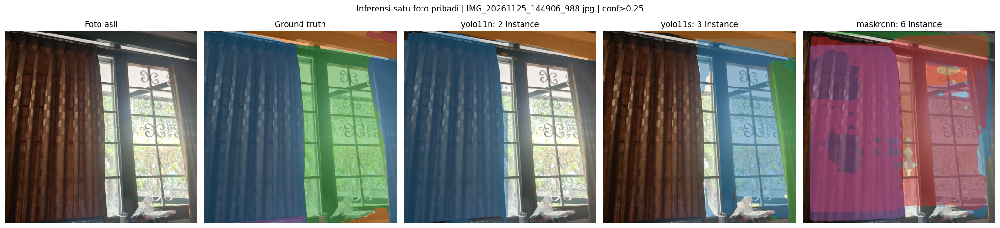

Gambar demo disimpan: /kaggle/working/instance_seg_023/one_personal_image_inference.png


In [31]:
# Satu foto dari dataset pribadi: hasil asli vs anotasi vs ketiga model
DEMO_IMAGE_ID = sorted(PERSONAL_IMG_PATHS)[0]
DEMO_INFO = next(im for im in PERSONAL_RAW['images'] if int(im['id'])==DEMO_IMAGE_ID)
DEMO_IMAGE = PERSONAL_IMG_PATHS[DEMO_IMAGE_ID]
print('Foto demo:',DEMO_IMAGE)

from PIL import Image
rgb=np.array(Image.open(DEMO_IMAGE).convert('RGB'))
h,w=rgb.shape[:2]
by_image={}
for a in PERSONAL_RAW['annotations']:by_image.setdefault(int(a['image_id']),[]).append(a)
fig,axs=plt.subplots(1,5,figsize=(21,5))
axs[0].imshow(rgb);axs[0].set_title('Foto asli')
gt_overlay,_=overlay_rles(rgb,by_image.get(DEMO_IMAGE_ID,[]),h,w)
axs[1].imshow(gt_overlay);axs[1].set_title('Ground truth')
for ax,name in zip(axs[2:],('yolo11n','yolo11s','maskrcnn')):
    pred_file=OUT/f'predictions_{name}_100_personal.json'
    assert pred_file.exists(),f'Prediksi model belum ada: {pred_file}'
    all_preds=json.loads(pred_file.read_text())
    selected=[a for a in all_preds if int(a['image_id'])==DEMO_IMAGE_ID and float(a.get('score',0))>=DEMO_CONF]
    pred_overlay,_=overlay_rles(rgb,selected,h,w)
    ax.imshow(pred_overlay);ax.set_title(f'{name}: {len(selected)} instance')
for ax in axs:ax.axis('off')
plt.suptitle(f'Inferensi satu foto pribadi | {DEMO_IMAGE.name} | conf≥{DEMO_CONF}')
plt.tight_layout();plt.savefig(OUT/'one_personal_image_inference.png',dpi=160,bbox_inches='tight');plt.show()
print('Gambar demo disimpan:',OUT/'one_personal_image_inference.png')

## 26. Arsip artefak evaluasi dan dokumen pendukung

Hasil metrik, grafik, audit gambar, analisis kegagalan, dan berkas dokumentasi ringan dikumpulkan menjadi ZIP. Checkpoint berukuran besar tetap disimpan dalam output Kaggle agar arsip laporan tidak membengkak.

In [32]:
import zipfile
archive=ROOT/'instance_seg_023_evidence.zip'
# Arsip selektif: hindari memasukkan bobot besar/dataset secara tak sengaja.
evidence=[p for p in OUT.rglob('*') if p.is_file() and p.suffix.lower() in {'.csv','.json','.yaml','.png','.jpg','.txt'}]
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in evidence: z.write(p,p.relative_to(OUT))
print('Bukti ringan:',archive,'jumlah file:',len(evidence))
print('Weights disimpan terpisah:',RUNS)
print('Simpan Kaggle Version agar bobot & output tidak hilang!')

Bukti ringan: /kaggle/working/instance_seg_023_evidence.zip jumlah file: 2073
Weights disimpan terpisah: /kaggle/working/instance_seg_023/runs
Simpan Kaggle Version agar bobot & output tidak hilang!


## Catatan validitas dan keterbatasan

- Hasil sembilan konfigurasi hanya dinyatakan lengkap apabila seluruh checkpoint dan hasil evaluasi benar-benar tersedia.
- Angka AP pada dua foto adalah evaluasi awal dan tidak mewakili evaluasi minimal 40 foto yang diwajibkan.
- Penggunaan subset data 25%, 50%, dan 100% dilakukan dengan seed tetap; penentuan model terbaik harus mempertimbangkan ukuran sampel, ketidakseimbangan kelas, dan pergeseran domain.
- Hipotesis sebelum training pertama harus berasal dari catatan yang benar-benar dibuat sebelum training, bukan dibuat mundur.
- Repository Git dengan riwayat commit, dokumentasi penggunaan GPU, metadata foto asli, minimal lima kasus kegagalan, dan demo langsung tetap memerlukan bukti tersendiri.
